### Notebook subission
This notebook contains the original generation scripts for the results and figures sent in the paper The Ruler and the Judge, for traceability.

In [1]:
import sys
sys.path.append("../src")
sys.path.append("..")

In [2]:
import pandas as pd
import os

def create_result_filedict(folder_path):
    filedict = {}
    for filename in os.listdir(folder_path):
        if filename.endswith(".parquet"):
            dimension = filename.split("_")[0]
            filedict[filename] = pd.read_parquet(os.path.join(folder_path, filename))
    return filedict

import glob
import os

import sys
sys.path.append("..")
from src.lm_bmfrm.data_preprocess import load_all_human_judgments, load_hanna, load_hitz_basse

def baseline(dataset_name):
    if dataset_name in {"summeval", "summeval_synth"}:
        df_human = load_all_human_judgments(use_summeval_hf=True)
    elif dataset_name == "hanna":
        df_human = load_hanna()
    elif dataset_name == "hitz_basse":
        df_human = load_hitz_basse()
    elif dataset_name == "hitz_basse_vas":
        df_human = load_hitz_basse(split="eu")
    df_human["is_llm"] = False

    judge_folder = "llm_judge_outputs" + "/" + dataset_name.lower().replace("-", "_")
    judge_files = glob.glob(os.path.join(judge_folder, "*.parquet"))
    j_df = []
    for file in judge_files:
        _j_df = pd.read_parquet(file).copy()
        if "generated_score" in _j_df.columns:
            _j_df = _j_df.rename(columns={"generated_score": "score"})
        if "score" in _j_df.columns:
            _j_df = _j_df.dropna(subset=["score"])

        j_df.append(_j_df)

    j_df = pd.concat(j_df, ignore_index=True)
    return df_human, j_df

/opt/conda/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Empirical

### Figure 1

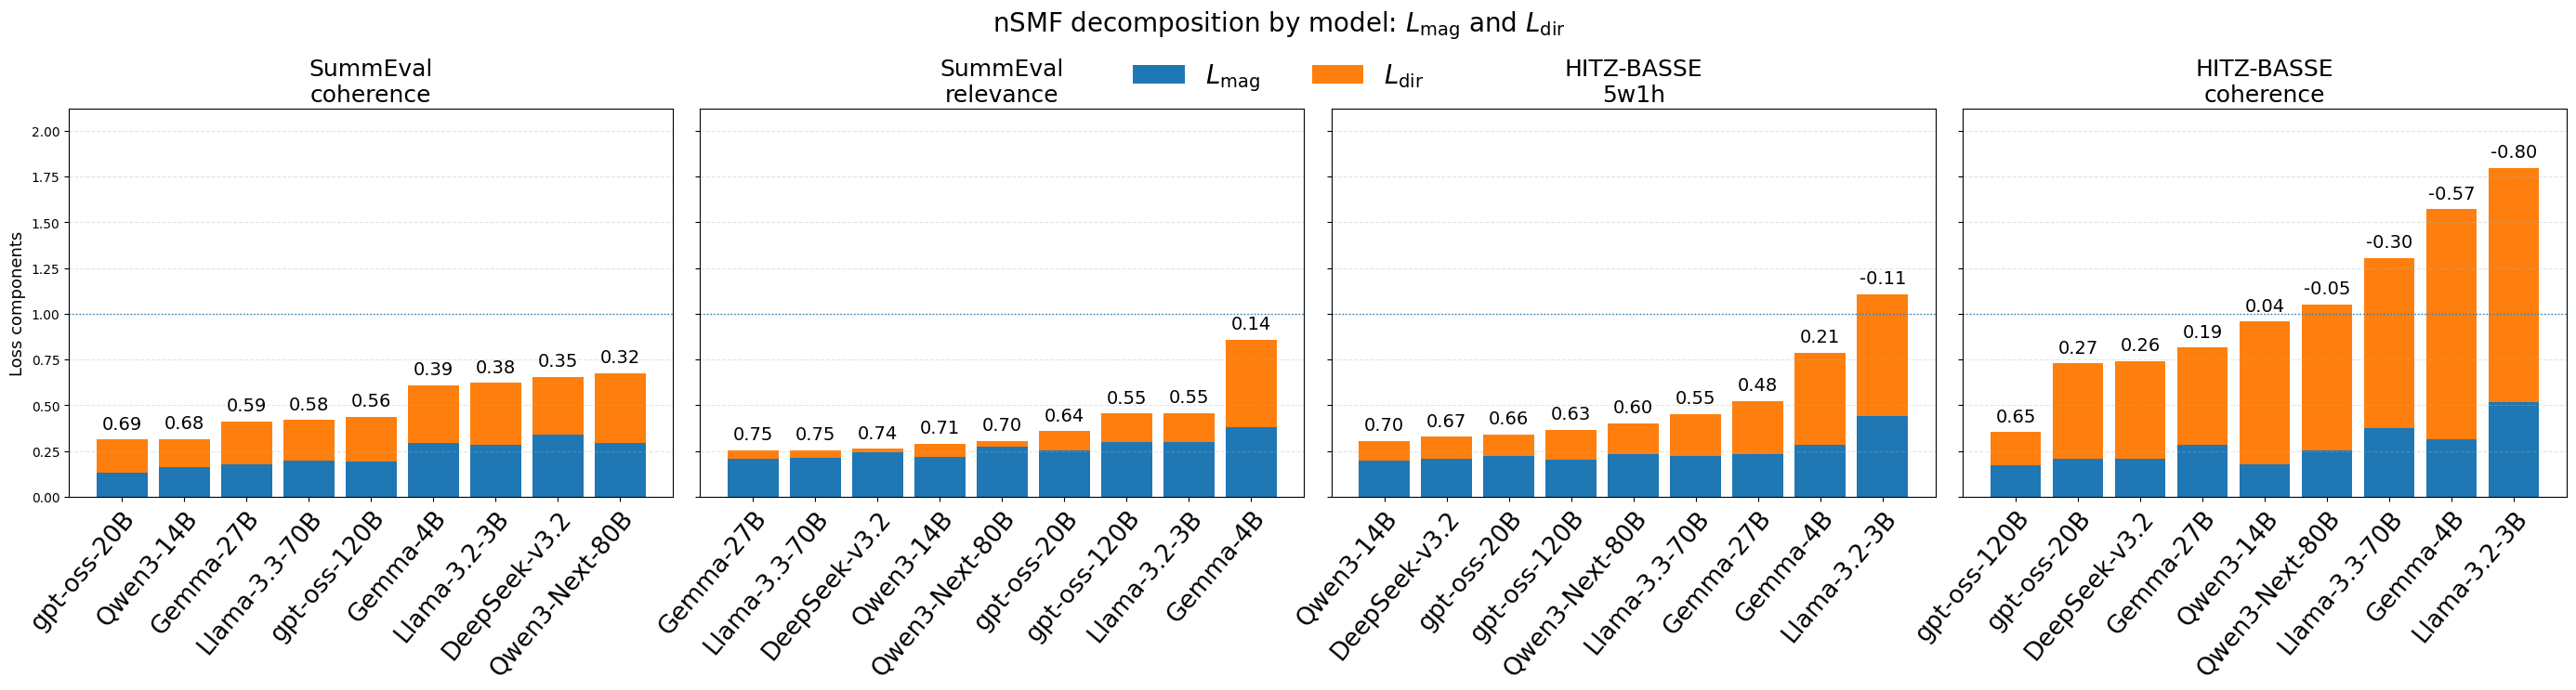

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# Configuration
# ============================================================

# Submission results directory
DATA_DIR = Path("../results_submission")

SUMMEVAL_FILE = DATA_DIR / "summeval_MC_per_judge_linspace_20260505_024534/leaderboard_results.parquet"
HITZ_FILE = DATA_DIR / "hitz_basse_MC_per_judge_linspace_20260425_232559/leaderboard_results.parquet"

# Choose the 4 dataset/dimension panels you want
PANELS = [
    ("SummEval", "coherence"),
    ("SummEval", "relevance"),
    ("HITZ-BASSE", "5w1h"),
    ("HITZ-BASSE", "coherence"),
]

# Sort models within each panel by one of: "NFSM", "Spearman", "Model"
SORT_BY = "NFSM"
SORT_ASCENDING = False

# Output file
OUTPUT_FILE = DATA_DIR / "stacked_loss_panels_1x4.png"

# Optional shortening of model names for readability
MODEL_NAME_MAP = {
    "openai/gpt-oss-120b": "gpt-oss-120B",
    "openai/gpt-oss-20b": "gpt-oss-20B",
    "Qwen/Qwen3-14B": "Qwen3-14B",
    "Qwen/Qwen3-Next-80B-A3B-Instruct": "Qwen3-Next-80B",
    "google/gemma-3-27b-it": "Gemma-27B",
    "google/gemma-3-4b-it": "Gemma-4B",
    "meta-llama/Llama-3.3-70B-Instruct": "Llama-3.3-70B",
    "meta-llama/Llama-3.2-3B-Instruct": "Llama-3.2-3B",
    "deepseek/deepseek-v3.2": "DeepSeek-v3.2",
    'meta-llama/llama-3.2-3b-instruct': 'Llama-3.2-3B',
    'meta-llama/llama-3.3-70b-instruct': 'Llama-3.3-70B',
    'qwen/qwen3-14b': 'Qwen3-14B',
    'qwen/qwen3-next-80b-a3b-instruct': 'Qwen3-Next-80B'
}

# ============================================================
# Load data
# ============================================================

sum_df = pd.read_parquet(SUMMEVAL_FILE)
hitz_df = pd.read_parquet(HITZ_FILE)

sum_df["Dataset"] = "SummEval"
hitz_df["Dataset"] = "HITZ-BASSE"

df = pd.concat([sum_df, hitz_df], ignore_index=True)

# Standardize expected columns
required_cols = [
    "Dataset",
    "Dimension",
    "Model",
    "NFSM",
    "NFSM Uncertainty Loss",
    "NFSM Direction Loss",
]
missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df["L_mag"] = df["NFSM Uncertainty Loss"]
df["L_dir"] = df["NFSM Direction Loss"]

# Short model names
df["ModelShort"] = df["Model"].map(MODEL_NAME_MAP).fillna(df["Model"])

# ============================================================
# Plot
# ============================================================

fig, axes = plt.subplots(
    1, 4,
    figsize=(28, 7.2),   # increase physical size
    sharey=True,
    gridspec_kw={"wspace": 0.045}
)

if len(PANELS) != 4:
    raise ValueError("PANELS must contain exactly 4 (dataset, dimension) pairs.")

global_max = 0.0
panel_data = []

for dataset, dimension in PANELS:
    sub = df[(df["Dataset"] == dataset) & (df["Dimension"] == dimension)].copy()
    if sub.empty:
        raise ValueError(f"No data found for panel ({dataset}, {dimension})")

    if SORT_BY in sub.columns:
        sub = sub.sort_values(SORT_BY, ascending=SORT_ASCENDING).reset_index(drop=True)
    else:
        raise ValueError(f"SORT_BY='{SORT_BY}' not found in dataframe columns.")

    sub["total_loss"] = sub["L_mag"] + sub["L_dir"]
    global_max = max(global_max, sub["total_loss"].max())
    panel_data.append(sub)

ymax = global_max * 1.18 if global_max > 0 else 1.0

for ax, (panel_cfg, sub) in zip(axes, zip(PANELS, panel_data)):
    dataset, dimension = panel_cfg

    x = np.arange(len(sub))
    width = 0.82

    ax.bar(
        x,
        sub["L_mag"],
        width=width,
        label=r"$L_{\mathrm{mag}}$",
    )
    ax.bar(
        x,
        sub["L_dir"],
        width=width,
        bottom=sub["L_mag"],
        label=r"$L_{\mathrm{dir}}$",
    )

    for xi, total, nsmf in zip(x, sub["total_loss"], sub["NFSM"]):
        ax.text(
            xi,
            total + 0.018 * ymax,
            f"{nsmf:.2f}",
            ha="center",
            va="bottom",
            fontsize=14,
        )

    ax.set_title(f"{dataset}\n{dimension}", fontsize=18, pad=6)
    ax.set_xticks(x)
    ax.set_xticklabels(
        sub["ModelShort"],
        rotation=50,
        ha="right",
        rotation_mode="anchor",
        fontsize=19,
    )
    ax.set_ylim(0, ymax)
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.axhline(1.0, linestyle=":", linewidth=1)

    # Remove repeated y-axis clutter
    if ax is not axes[0]:
        ax.tick_params(axis="y", labelleft=False)

axes[0].set_ylabel("Loss components", fontsize=13)

# Shared legend inside top area, not above the figure
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 0.965),
    fontsize=20,
)

fig.suptitle(
    r"nSMF decomposition by model: $L_{\mathrm{mag}}$ and $L_{\mathrm{dir}}$",
    fontsize=20,
    y=1.01,
)

fig.subplots_adjust(
    left=0.035,
    right=0.995,
    bottom=0.28,
    top=0.86,
    wspace=0.045
)

plt.savefig(OUTPUT_FILE, dpi=600, bbox_inches="tight", format="pdf")
plt.show()

### Table 4

In [4]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path("../results_submission")

FILES = {
    "SummEval": BASE_DIR / "summeval_MC_per_judge_linspace_20260505_024534/predictions.parquet",
    "HiTZ-BASSE": BASE_DIR / "hitz_basse_MC_per_judge_linspace_20260425_232559/predictions.parquet",
}

DIM_ORDER = {
    "SummEval": ["coherence", "consistency", "fluency", "relevance"],
    "HiTZ-BASSE": ["5w1h", "coherence", "consistency", "fluency", "relevance"],
}

DIM_LABEL = {
    "5w1h": "5W1H",
    "coherence": "coherence",
    "consistency": "consistency",
    "fluency": "fluency",
    "relevance": "relevance",
}

def normalize_dimension(series: pd.Series) -> pd.Series:
    return series.astype(str).str.strip().str.casefold()


def reconstruct_judge_level_emd(
    dataset: str,
    path: Path,
) -> pd.DataFrame:
    """
    predictions.parquet contains one EMD mean per:
        held-out system × judge × dimension

    Reconstruct one item-weighted EMD value per:
        judge × dimension
    """
    if not path.exists():
        raise FileNotFoundError(f"{dataset}: file not found: {path}")

    df = pd.read_parquet(path).copy()

    required = {
        "system_id",
        "judge_model",
        "dimension",
        "emd_raw",
        "emd_pred",
        "n_items_eval",
    }
    missing = required - set(df.columns)

    if missing:
        raise KeyError(
            f"{dataset}: missing columns {sorted(missing)}. "
            f"Available columns: {list(df.columns)}"
        )

    df["dataset"] = dataset
    df["dimension"] = normalize_dimension(df["dimension"])

    for col in ["emd_raw", "emd_pred", "n_items_eval"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    valid = (
        df["emd_raw"].notna()
        & df["emd_pred"].notna()
        & df["n_items_eval"].notna()
        & (df["n_items_eval"] > 0)
    )
    df = df.loc[valid].copy()

    key = [
        "dataset",
        "dimension",
        "judge_model",
        "system_id",
    ]

    duplicates = df.duplicated(key, keep=False)
    if duplicates.any():
        examples = (
            df.loc[duplicates, key]
            .drop_duplicates()
            .head(10)
            .to_dict("records")
        )
        raise ValueError(
            f"{dataset}: duplicate prediction rows detected. "
            f"Examples: {examples}"
        )

    # Undo the stored per-system mean using its item count.
    df["raw_emd_sum"] = df["emd_raw"] * df["n_items_eval"]
    df["calibrated_emd_sum"] = (
        df["emd_pred"] * df["n_items_eval"]
    )

    judge_level = (
        df.groupby(
            ["dataset", "dimension", "judge_model"],
            as_index=False,
        )
        .agg(
            n_items_eval=("n_items_eval", "sum"),
            raw_emd_sum=("raw_emd_sum", "sum"),
            calibrated_emd_sum=("calibrated_emd_sum", "sum"),
        )
    )

    judge_level["Raw EMD"] = (
        judge_level["raw_emd_sum"]
        / judge_level["n_items_eval"]
    )
    judge_level["Calibrated EMD"] = (
        judge_level["calibrated_emd_sum"]
        / judge_level["n_items_eval"]
    )
    judge_level["Delta"] = (
        judge_level["Raw EMD"]
        - judge_level["Calibrated EMD"]
    )
    judge_level["improved"] = judge_level["Delta"] > 0

    return judge_level[
        [
            "dataset",
            "dimension",
            "judge_model",
            "Raw EMD",
            "Calibrated EMD",
            "Delta",
            "improved",
        ]
    ]


# =============================================================================
# BUILD PAPER-STYLE TABLE
# =============================================================================

judge_level_tables = []
table_rows = []

for dataset, path in FILES.items():
    judge_level = reconstruct_judge_level_emd(
        dataset,
        path,
    )
    judge_level_tables.append(judge_level)

    dimension_summary = (
        judge_level.groupby(
            ["dataset", "dimension"],
            as_index=False,
        )
        .agg(
            n_judges=("judge_model", "nunique"),
            n_improved=("improved", "sum"),
            raw_emd=("Raw EMD", "mean"),
            calibrated_emd=("Calibrated EMD", "mean"),
            delta=("Delta", "mean"),
        )
    )

    order_map = {
        dimension: position
        for position, dimension in enumerate(
            DIM_ORDER[dataset]
        )
    }

    unexpected = (
        set(dimension_summary["dimension"])
        - set(order_map)
    )
    if unexpected:
        raise ValueError(
            f"{dataset}: unexpected dimensions: "
            f"{sorted(unexpected)}"
        )

    dimension_summary["_order"] = (
        dimension_summary["dimension"].map(order_map)
    )
    dimension_summary = dimension_summary.sort_values(
        "_order"
    )

    for row in dimension_summary.itertuples(index=False):
        table_rows.append(
            {
                "Dataset": dataset,
                "Dimension": DIM_LABEL.get(
                    row.dimension,
                    row.dimension,
                ),
                "Improved": (
                    f"{int(row.n_improved)}"
                    f"/{int(row.n_judges)}"
                ),
                "Raw EMD": float(row.raw_emd),
                "Calibrated EMD": float(
                    row.calibrated_emd
                ),
                "Delta": float(row.delta),
            }
        )


# Overall row: one observation per judge–dimension.
all_judge_dimensions = pd.concat(
    judge_level_tables,
    ignore_index=True,
)

table_rows.append(
    {
        "Dataset": "All",
        "Dimension": "all dimensions",
        "Improved": (
            f"{int(all_judge_dimensions['improved'].sum())}"
            f"/{len(all_judge_dimensions)}"
        ),
        "Raw EMD": (
            all_judge_dimensions["Raw EMD"].mean()
        ),
        "Calibrated EMD": (
            all_judge_dimensions["Calibrated EMD"].mean()
        ),
        "Delta": (
            all_judge_dimensions["Delta"].mean()
        ),
    }
)

summary = pd.DataFrame(
    table_rows,
    columns=[
        "Dataset",
        "Dimension",
        "Improved",
        "Raw EMD",
        "Calibrated EMD",
        "Delta",
    ],
)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}",
    )
)

summary.to_csv(
    "distributional_emd_paper_table.csv",
    index=False,
)
from pathlib import Path

import numpy as np
import pandas as pd


# =============================================================================
# CONFIGURATION
# =============================================================================

BASE_DIR = Path("../results_submission")

FILES = {
    "SummEval": (
        BASE_DIR
        / "summeval_MC_per_judge_linspace_20260505_024534"
        / "predictions.parquet"
    ),
    "HiTZ-BASSE": (
        BASE_DIR
        / "hitz_basse_MC_per_judge_linspace_20260425_232559"
        / "predictions.parquet"
    ),
}

# Optional archived HiTZ-BASSE aggregate used to verify that the correct
# predictions.parquet has been selected.
ARCHIVED_HITZ_CSV = (
    Path("../results_previous/aa_final")
    / "hitz_basse_step3_distrib_fidelity_predictions.csv"
)

OUTPUT_CSV = Path("distributional_emd_paper_table.csv")
OUTPUT_LATEX = Path("distributional_emd_paper_table.tex")

DIM_ORDER = {
    "SummEval": [
        "coherence",
        "consistency",
        "fluency",
        "relevance",
    ],
    "HiTZ-BASSE": [
        "5w1h",
        "coherence",
        "consistency",
        "fluency",
        "relevance",
    ],
}

DIM_LABEL = {
    "5w1h": "5W1H",
    "coherence": "coherence",
    "consistency": "consistency",
    "fluency": "fluency",
    "relevance": "relevance",
}


# =============================================================================
# HELPERS
# =============================================================================

def normalize_dimension(series: pd.Series) -> pd.Series:
    """Normalize dimension labels for matching and grouping."""
    return (
        series.astype(str)
        .str.strip()
        .str.casefold()
    )


def normalize_judge(series: pd.Series) -> pd.Series:
    """Normalize judge identifiers for comparisons."""
    return (
        series.astype(str)
        .str.strip()
        .str.casefold()
    )


def reconstruct_judge_level_emd(
    dataset: str,
    path: Path,
) -> pd.DataFrame:
    """
    Reconstruct one EMD value per judge and dimension.

    Each predictions.parquet row contains one mean EMD value for:

        held-out system × judge × dimension

    To reproduce the original pipeline and archived aggregate table, the
    held-out-system values are averaged equally. They are NOT weighted by
    n_items_eval.

    Returns one row per:

        dataset × dimension × judge
    """
    if not path.exists():
        raise FileNotFoundError(
            f"{dataset}: predictions file not found:\n{path.resolve()}"
        )

    df = pd.read_parquet(path).copy()

    required = {
        "system_id",
        "judge_model",
        "dimension",
        "emd_raw",
        "emd_pred",
    }

    missing = required - set(df.columns)

    if missing:
        raise KeyError(
            f"{dataset}: missing required columns {sorted(missing)}.\n"
            f"Available columns:\n{list(df.columns)}"
        )

    df["dataset"] = dataset
    df["dimension"] = normalize_dimension(df["dimension"])
    df["judge_model"] = df["judge_model"].astype(str).str.strip()
    df["system_id"] = df["system_id"].astype(str).str.strip()

    for column in ["emd_raw", "emd_pred"]:
        df[column] = pd.to_numeric(
            df[column],
            errors="coerce",
        )

    # Use paired valid rows so raw and calibrated EMD are always compared
    # over the same held-out systems.
    invalid = (
        df["emd_raw"].isna()
        | df["emd_pred"].isna()
    )

    if invalid.any():
        print(
            f"{dataset}: dropping {int(invalid.sum())} rows "
            "with missing raw or calibrated EMD."
        )

    df = df.loc[~invalid].copy()

    if df.empty:
        raise ValueError(
            f"{dataset}: no valid prediction rows remain."
        )

    key = [
        "dataset",
        "dimension",
        "judge_model",
        "system_id",
    ]

    duplicate_mask = df.duplicated(
        key,
        keep=False,
    )

    if duplicate_mask.any():
        examples = (
            df.loc[duplicate_mask, key]
            .drop_duplicates()
            .sort_values(key)
            .head(20)
            .to_dict("records")
        )

        raise ValueError(
            f"{dataset}: duplicate rows were detected for "
            "dataset × dimension × judge × system.\n"
            f"Examples:\n{examples}"
        )

    expected_dimensions = set(DIM_ORDER[dataset])
    observed_dimensions = set(df["dimension"])

    unexpected_dimensions = (
        observed_dimensions - expected_dimensions
    )

    if unexpected_dimensions:
        raise ValueError(
            f"{dataset}: unexpected dimensions found: "
            f"{sorted(unexpected_dimensions)}"
        )

    missing_dimensions = (
        expected_dimensions - observed_dimensions
    )

    if missing_dimensions:
        raise ValueError(
            f"{dataset}: expected dimensions are absent: "
            f"{sorted(missing_dimensions)}"
        )

    # IMPORTANT:
    # This is an unweighted mean across held-out systems, matching the
    # original Stage-3 aggregation.
    judge_level = (
        df.groupby(
            [
                "dataset",
                "dimension",
                "judge_model",
            ],
            as_index=False,
            sort=False,
        )
        .agg(
            n_systems=(
                "system_id",
                "nunique",
            ),
            Raw_EMD=(
                "emd_raw",
                "mean",
            ),
            Calibrated_EMD=(
                "emd_pred",
                "mean",
            ),
        )
    )

    judge_level["Delta"] = (
        judge_level["Raw_EMD"]
        - judge_level["Calibrated_EMD"]
    )

    judge_level["improved"] = (
        judge_level["Delta"] > 0
    )

    judge_level = judge_level.rename(
        columns={
            "Raw_EMD": "Raw EMD",
            "Calibrated_EMD": "Calibrated EMD",
        }
    )

    return judge_level[
        [
            "dataset",
            "dimension",
            "judge_model",
            "n_systems",
            "Raw EMD",
            "Calibrated EMD",
            "Delta",
            "improved",
        ]
    ]


def validate_system_coverage(
    judge_level: pd.DataFrame,
) -> None:
    """
    Report variation in the number of held-out systems represented for each
    judge–dimension combination.
    """
    coverage_summary = (
        judge_level.groupby(
            ["dataset", "dimension"],
            as_index=False,
        )
        .agg(
            n_judges=("judge_model", "nunique"),
            minimum_systems=("n_systems", "min"),
            maximum_systems=("n_systems", "max"),
        )
    )

    print("\nHeld-out-system coverage:")
    print(
        coverage_summary.to_string(
            index=False,
        )
    )

    inconsistent = coverage_summary.loc[
        coverage_summary["minimum_systems"]
        != coverage_summary["maximum_systems"]
    ]

    if not inconsistent.empty:
        print(
            "\nWARNING: some judges have different numbers of held-out "
            "systems within the same dataset and dimension:"
        )
        print(
            inconsistent.to_string(
                index=False,
            )
        )


def validate_against_archived_hitz(
    reconstructed: pd.DataFrame,
    archived_path: Path,
    tolerance: float = 1e-12,
) -> None:
    """
    Compare reconstructed HiTZ-BASSE judge-level EMD values against the
    archived aggregate CSV.

    This check is optional and runs only when archived_path exists.
    """
    if not archived_path.exists():
        print(
            "\nArchived HiTZ-BASSE CSV not found; "
            "skipping provenance validation:"
        )
        print(archived_path.resolve())
        return

    archived = pd.read_csv(archived_path).copy()

    required = {
        "dimension",
        "judge_model",
        "emd_raw",
        "emd_pred",
    }

    missing = required - set(archived.columns)

    if missing:
        raise KeyError(
            "Archived HiTZ-BASSE CSV is missing columns "
            f"{sorted(missing)}.\n"
            f"Available columns:\n{list(archived.columns)}"
        )

    archived["dimension"] = normalize_dimension(
        archived["dimension"]
    )
    archived["judge_key"] = normalize_judge(
        archived["judge_model"]
    )

    for column in ["emd_raw", "emd_pred"]:
        archived[column] = pd.to_numeric(
            archived[column],
            errors="coerce",
        )

    actual = reconstructed.loc[
        reconstructed["dataset"] == "HiTZ-BASSE"
    ].copy()

    actual["judge_key"] = normalize_judge(
        actual["judge_model"]
    )

    comparison = archived.merge(
        actual[
            [
                "dimension",
                "judge_key",
                "judge_model",
                "Raw EMD",
                "Calibrated EMD",
            ]
        ],
        on=[
            "dimension",
            "judge_key",
        ],
        how="outer",
        suffixes=(
            "_archived",
            "_reconstructed",
        ),
        indicator=True,
        validate="one_to_one",
    )

    comparison["raw_abs_error"] = (
        comparison["emd_raw"]
        - comparison["Raw EMD"]
    ).abs()

    comparison["pred_abs_error"] = (
        comparison["emd_pred"]
        - comparison["Calibrated EMD"]
    ).abs()

    columns_to_print = [
        "dimension",
        "judge_model_archived",
        "judge_model_reconstructed",
        "emd_raw",
        "Raw EMD",
        "raw_abs_error",
        "emd_pred",
        "Calibrated EMD",
        "pred_abs_error",
        "_merge",
    ]

    print("\nHiTZ-BASSE archived CSV comparison:")
    print(
        comparison[columns_to_print]
        .sort_values(
            [
                "dimension",
                "judge_model_archived",
            ],
            na_position="last",
        )
        .to_string(
            index=False,
            float_format=lambda value: f"{value:.15g}",
        )
    )

    unmatched = comparison["_merge"] != "both"

    if unmatched.any():
        raise AssertionError(
            "The archived and reconstructed files do not contain "
            "the same judge–dimension combinations."
        )

    max_raw_error = comparison["raw_abs_error"].max()
    max_pred_error = comparison["pred_abs_error"].max()

    print(
        "\nMaximum absolute reconstruction errors:"
    )
    print(f"  Raw EMD:        {max_raw_error:.16g}")
    print(f"  Calibrated EMD: {max_pred_error:.16g}")

    if max_raw_error > tolerance:
        raise AssertionError(
            "Raw EMD does not reproduce the archived CSV. "
            f"Maximum error: {max_raw_error:.16g}"
        )

    if max_pred_error > tolerance:
        raise AssertionError(
            "Calibrated EMD does not reproduce the archived CSV. "
            f"Maximum error: {max_pred_error:.16g}"
        )

    print(
        "\nExact validation passed: the selected HiTZ-BASSE "
        "predictions.parquet reproduces the archived aggregate CSV."
    )


def build_summary_table(
    judge_level_tables: list[pd.DataFrame],
) -> pd.DataFrame:
    """
    Build the paper-style dataset × dimension summary.

    Each dimension-level EMD is the arithmetic mean across judges after each
    judge's EMD has been reconstructed as an arithmetic mean across held-out
    systems.
    """
    table_rows = []

    for judge_level in judge_level_tables:
        datasets = judge_level["dataset"].unique()

        if len(datasets) != 1:
            raise ValueError(
                "Each judge-level table must contain exactly one dataset."
            )

        dataset = datasets[0]

        dimension_summary = (
            judge_level.groupby(
                [
                    "dataset",
                    "dimension",
                ],
                as_index=False,
                sort=False,
            )
            .agg(
                n_judges=(
                    "judge_model",
                    "nunique",
                ),
                n_improved=(
                    "improved",
                    "sum",
                ),
                raw_emd=(
                    "Raw EMD",
                    "mean",
                ),
                calibrated_emd=(
                    "Calibrated EMD",
                    "mean",
                ),
                delta=(
                    "Delta",
                    "mean",
                ),
            )
        )

        order_map = {
            dimension: position
            for position, dimension in enumerate(
                DIM_ORDER[dataset]
            )
        }

        unexpected = (
            set(dimension_summary["dimension"])
            - set(order_map)
        )

        if unexpected:
            raise ValueError(
                f"{dataset}: unexpected dimensions in summary: "
                f"{sorted(unexpected)}"
            )

        dimension_summary["_order"] = (
            dimension_summary["dimension"]
            .map(order_map)
        )

        dimension_summary = (
            dimension_summary.sort_values(
                "_order"
            )
            .reset_index(drop=True)
        )

        for row in dimension_summary.itertuples(
            index=False
        ):
            table_rows.append(
                {
                    "Dataset": dataset,
                    "Dimension": DIM_LABEL.get(
                        row.dimension,
                        row.dimension,
                    ),
                    "Improved": (
                        f"{int(row.n_improved)}"
                        f"/{int(row.n_judges)}"
                    ),
                    "Raw EMD": float(
                        row.raw_emd
                    ),
                    "Calibrated EMD": float(
                        row.calibrated_emd
                    ),
                    "Delta": float(
                        row.delta
                    ),
                }
            )

    # Overall row: one equally weighted observation per judge–dimension pair.
    all_judge_dimensions = pd.concat(
        judge_level_tables,
        ignore_index=True,
    )

    table_rows.append(
        {
            "Dataset": "All",
            "Dimension": "all dimensions",
            "Improved": (
                f"{int(all_judge_dimensions['improved'].sum())}"
                f"/{len(all_judge_dimensions)}"
            ),
            "Raw EMD": float(
                all_judge_dimensions["Raw EMD"].mean()
            ),
            "Calibrated EMD": float(
                all_judge_dimensions[
                    "Calibrated EMD"
                ].mean()
            ),
            "Delta": float(
                all_judge_dimensions["Delta"].mean()
            ),
        }
    )

    return pd.DataFrame(
        table_rows,
        columns=[
            "Dataset",
            "Dimension",
            "Improved",
            "Raw EMD",
            "Calibrated EMD",
            "Delta",
        ],
    )


def build_latex_table(
    summary: pd.DataFrame,
) -> str:
    """Create the LaTeX table used in the paper."""
    latex_rows = []
    previous_dataset = None

    for row in summary.itertuples(index=False):
        dataset = row.Dataset
        dimension = row.Dimension
        improved = row.Improved
        raw_emd = getattr(row, "_3")
        calibrated_emd = getattr(row, "_4")
        delta = row.Delta

        if (
            previous_dataset is not None
            and dataset != previous_dataset
        ):
            latex_rows.append(r"\midrule")

        latex_rows.append(
            f"{dataset} "
            f"& {dimension} "
            f"& {improved} "
            f"& {raw_emd:.3f} "
            f"& {calibrated_emd:.3f} "
            f"& {delta:.3f} "
            r"\\"
        )

        previous_dataset = dataset

    latex_table = (
        r"""
\begin{table}[ht]
\centering
\small
\setlength{\tabcolsep}{4pt}
\caption{
Distributional fidelity of calibrated judge predictions.
Raw EMD compares the raw judge score distribution against the empirical
human score histogram. Calibrated EMD maps the judge-based posterior
through the human response model before computing EMD. Lower is better.
``Improved'' counts judges for which calibrated EMD is lower than raw EMD.
}
\label{tab:distributional-emd}
\begin{tabular}{llrrrr}
\toprule
\textbf{Dataset}
& \textbf{Dimension}
& \textbf{Improved}
& \textbf{Raw EMD $\downarrow$}
& \textbf{Calibrated EMD $\downarrow$}
& $\boldsymbol{\Delta}$ \\
\midrule
"""
        + "\n".join(latex_rows)
        + r"""
\bottomrule
\end{tabular}
\end{table}
"""
    )

    return latex_table.strip() + "\n"


# =============================================================================
# MAIN
# =============================================================================

def main() -> None:
    judge_level_tables = []

    print("Input prediction files:")

    for dataset, path in FILES.items():
        print(f"  {dataset}: {path.resolve()}")

        judge_level = reconstruct_judge_level_emd(
            dataset=dataset,
            path=path,
        )

        judge_level_tables.append(
            judge_level
        )

    all_judge_level = pd.concat(
        judge_level_tables,
        ignore_index=True,
    )

    validate_system_coverage(
        all_judge_level
    )

    # This confirms whether the selected older HiTZ-BASSE parquet is the
    # source of hitz_basse_step3_distrib_fidelity_predictions.csv.
    validate_against_archived_hitz(
        reconstructed=all_judge_level,
        archived_path=ARCHIVED_HITZ_CSV,
    )

    summary = build_summary_table(
        judge_level_tables
    )

    print("\nPaper-style distributional EMD table:")
    print(
        summary.to_string(
            index=False,
            float_format=lambda value: f"{value:.3f}",
        )
    )

    summary.to_csv(
        OUTPUT_CSV,
        index=False,
    )

    latex_table = build_latex_table(
        summary
    )

    OUTPUT_LATEX.write_text(
        latex_table,
        encoding="utf-8",
    )

    print("\nLaTeX table:")
    print(latex_table)

    print("\nOutputs written:")
    print(f"  CSV:   {OUTPUT_CSV.resolve()}")
    print(f"  LaTeX: {OUTPUT_LATEX.resolve()}")


if __name__ == "__main__":
    main()

# =============================================================================
# LATEX: SAME FORMAT AS THE PAPER TABLE
# =============================================================================

latex_rows = []
previous_dataset = None

for _, row in summary.iterrows():
    dataset = row["Dataset"]

    if (
        previous_dataset is not None
        and dataset != previous_dataset
    ):
        latex_rows.append(r"\midrule")

    latex_rows.append(
        f"{dataset} "
        f"& {row['Dimension']} "
        f"& {row['Improved']} "
        f"& {row['Raw EMD']:.3f} "
        f"& {row['Calibrated EMD']:.3f} "
        f"& {row['Delta']:.3f} \\\\"
    )

    previous_dataset = dataset


latex_table = r"""
\begin{table}[ht]
\centering
\small
\setlength{\tabcolsep}{4pt}
\caption{
Distributional fidelity of calibrated judge predictions. Raw EMD compares the raw judge score distribution against the empirical human score histogram. Calibrated EMD maps the judge-based posterior through the human response model before computing EMD. Lower is better. ``Improved'' counts judges for which calibrated EMD is lower than raw EMD.
}
\label{tab:distributional-emd}
\begin{tabular}{llrrrr}
\toprule
\textbf{Dataset}
& \textbf{Dimension}
& \textbf{Improved}
& \textbf{Raw EMD $\downarrow$}
& \textbf{Calibrated EMD $\downarrow$}
& $\boldsymbol{\Delta}$ \\
\midrule
""" + "\n".join(latex_rows) + r"""
\bottomrule
\end{tabular}
\end{table}
"""

print("\n" + latex_table)

   Dataset      Dimension Improved  Raw EMD  Calibrated EMD  Delta
  SummEval      coherence      9/9    1.580           1.258  0.322
  SummEval    consistency      6/9    0.419           0.271  0.148
  SummEval        fluency      9/9    1.923           0.402  1.522
  SummEval      relevance      9/9    2.150           1.297  0.853
HiTZ-BASSE           5W1H      8/9    1.861           1.584  0.276
HiTZ-BASSE      coherence      2/9    2.064           2.124 -0.061
HiTZ-BASSE    consistency      2/9    1.165           1.032  0.133
HiTZ-BASSE        fluency      4/9    0.512           0.437  0.076
HiTZ-BASSE      relevance      9/9    2.001           1.805  0.196
       All all dimensions    58/81    1.519           1.134  0.385
Input prediction files:
  SummEval: /workspaces/TheRulerAndTheJudge/results_submission/summeval_MC_per_judge_linspace_20260505_024534/predictions.parquet
  HiTZ-BASSE: /workspaces/TheRulerAndTheJudge/results_submission/hitz_basse_MC_per_judge_linspace_20260425_23

### Table 1

In [5]:
sys.path.append("..")
from __future__ import annotations

from itertools import combinations
from pathlib import Path
from typing import Iterable, Optional

import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from src.lm_bmfrm.data_preprocess import load_all_human_judgments


# =============================================================================
# CONFIGURATION
# =============================================================================
RESULT_ROOT = Path("../results_submission")

# Main synthetic suite plus the separately fitted targeted-pair flip.
# Replace timestamps here if your definitive experiment folders differ.
RUN_DIRS = [
    RESULT_ROOT / "summeval_synth_MC_per_judge_linspace_20260505_030252",
    RESULT_ROOT / "summeval_synth_MC_per_judge_BITFLIP_linspace_20260505_090557",
]

# These are the raw synthetic judge outputs supplied to the evaluation pipeline.
RAW_JUDGE_DIR = Path("../llm_judge_outputs/summeval_synth")

DIMENSION = "coherence"
TAU_H = 0.80
TAU_L = 0.80

NAME_MAP = {
    "synthetic__00_empirical_identity":
        "Empirical identity",
    "synthetic__10_coherent_lenient_shift_plus1":
        "Lenient shift",
    "synthetic__13_category_collapse_3level":
        "3-level collapse",
    "synthetic__20_item_permute_within_system":
        "Within-system item permutation",
    "synthetic__60_random_noise_0p8":
        "Random noise control",
    "synthetic__m_compression_rho0p9":
        "Compression",
    "synthetic__m_overseparation_rho0p9":
        "Over-separation",
    "synthetic__m_false_confidence_close_rho0p9":
        "False confidence on close pairs",
    "synthetic__55_targeted_supported_pair_flip":
        "Targeted supported-pair flip",
}

ORDER = [
    "Empirical identity",
    "Lenient shift",
    "3-level collapse",
    "Within-system item permutation",
    "Random noise control",
    "Compression",
    "Over-separation",
    "False confidence on close pairs",
    "Targeted supported-pair flip",
]


# =============================================================================
# GENERIC HELPERS
# =============================================================================

def norm_key(value) -> str:
    return str(value).strip().casefold()


def first_column(
    df: pd.DataFrame,
    candidates: Iterable[str],
    *,
    required: bool = True,
) -> Optional[str]:
    lookup = {norm_key(column): column for column in df.columns}

    for candidate in candidates:
        key = norm_key(candidate)
        if key in lookup:
            return lookup[key]

    if required:
        raise KeyError(
            f"None of {list(candidates)} found. "
            f"Available columns: {list(df.columns)}"
        )

    return None


def require_file(path: Path) -> Path:
    if not path.exists():
        raise FileNotFoundError(path)
    return path


def safe_spearman(x, y) -> float:
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]

    if (
        len(x) < 3
        or np.std(x) < 1e-12
        or np.std(y) < 1e-12
    ):
        return np.nan

    result = spearmanr(x, y).correlation
    return float(result) if result is not None else np.nan


def fmt(value) -> str:
    if pd.isna(value):
        return "--"

    text = f"{float(value):.3f}"
    text = text.replace("-0.", "-.")
    text = text.replace("0.", ".")
    return text


# =============================================================================
# LOAD THE RAW HUMAN AND SYNTHETIC SCORES
# =============================================================================

def load_human_coherence() -> pd.DataFrame:
    human = load_all_human_judgments(
        use_summeval_hf=True,
    ).copy()

    if "is_llm" in human.columns:
        human = human[
            ~human["is_llm"].fillna(False).astype(bool)
        ].copy()

    required = {
        "system_id",
        "item_id",
        "dimension",
        "score",
    }
    missing = required - set(human.columns)

    if missing:
        raise KeyError(
            f"Human data lacks columns {sorted(missing)}"
        )

    human = human[
        human["dimension"].map(norm_key)
        == norm_key(DIMENSION)
    ].copy()

    human["system_id"] = human["system_id"].astype(str)
    human["item_id"] = human["item_id"].astype(str)
    human["score"] = pd.to_numeric(
        human["score"],
        errors="raise",
    )

    if human.empty:
        raise ValueError(
            f"No human rows found for {DIMENSION!r}"
        )

    return human


def load_raw_synthetic_scores() -> pd.DataFrame:
    files = sorted(
        RAW_JUDGE_DIR.glob(
            "synthetic_judges_reviewer_main_*.parquet"
        )
    )

    if not files:
        # Also support a single combined raw suite file.
        combined = (
            RAW_JUDGE_DIR
            / "synthetic_judges_reviewer_main.parquet"
        )
        if combined.exists():
            files = [combined]

    if not files:
        raise FileNotFoundError(
            "No raw reviewer-main synthetic judge files found "
            f"under {RAW_JUDGE_DIR}"
        )

    frames = []

    for path in files:
        frame = pd.read_parquet(path).copy()

        required = {
            "rater_id",
            "system_id",
            "item_id",
            "dimension",
            "score",
        }
        missing = required - set(frame.columns)

        if missing:
            raise KeyError(
                f"{path} lacks columns {sorted(missing)}"
            )

        frames.append(frame)

    synthetic = pd.concat(frames, ignore_index=True)

    synthetic = synthetic[
        synthetic["dimension"].map(norm_key)
        == norm_key(DIMENSION)
    ].copy()

    synthetic["rater_id"] = (
        synthetic["rater_id"].astype(str)
    )
    synthetic["system_id"] = (
        synthetic["system_id"].astype(str)
    )
    synthetic["item_id"] = (
        synthetic["item_id"].astype(str)
    )
    synthetic["score"] = pd.to_numeric(
        synthetic["score"],
        errors="raise",
    )

    synthetic = synthetic[
        synthetic["rater_id"].isin(NAME_MAP)
    ].copy()

    expected = set(NAME_MAP)
    observed = set(synthetic["rater_id"].unique())
    missing_judges = expected - observed

    if missing_judges:
        raise ValueError(
            "Raw synthetic files are missing judges: "
            f"{sorted(missing_judges)}"
        )

    # One synthetic score per judge × system × item is expected.
    key = ["rater_id", "system_id", "item_id"]
    duplicates = synthetic.duplicated(key, keep=False)

    if duplicates.any():
        examples = (
            synthetic.loc[duplicates, key]
            .drop_duplicates()
            .head(20)
        )
        raise ValueError(
            "Duplicate raw synthetic ratings found:\n"
            + examples.to_string(index=False)
        )

    return synthetic


# =============================================================================
# RECOMPUTE RAW SYSTEM- AND ITEM-LEVEL SPEARMAN
# =============================================================================

def compute_raw_correlations(
    synthetic: pd.DataFrame,
    human: pd.DataFrame,
) -> pd.DataFrame:
    human_system = (
        human.groupby("system_id")["score"]
        .mean()
        .sort_index()
    )

    human_system_item = (
        human.groupby(["system_id", "item_id"])["score"]
        .mean()
        .sort_index()
    )

    rows = []

    for judge, group in synthetic.groupby("rater_id"):
        synth_system = (
            group.groupby("system_id")["score"]
            .mean()
            .sort_index()
        )

        common_systems = (
            synth_system.index
            .intersection(human_system.index)
        )

        raw_system_spearman = safe_spearman(
            synth_system.loc[common_systems].values,
            human_system.loc[common_systems].values,
        )

        synth_system_item = (
            group.groupby(["system_id", "item_id"])["score"]
            .mean()
            .sort_index()
        )

        common_items = (
            synth_system_item.index
            .intersection(human_system_item.index)
        )

        raw_item_spearman = safe_spearman(
            synth_system_item.loc[common_items].values,
            human_system_item.loc[common_items].values,
        )

        rows.append(
            {
                "Model": str(judge),
                "raw_system_spearman_vs_human":
                    raw_system_spearman,
                "raw_item_spearman_vs_human":
                    raw_item_spearman,
                "n_systems_raw": len(common_systems),
                "n_system_items_raw": len(common_items),
            }
        )

    return pd.DataFrame(rows)


# =============================================================================
# LOAD THE STANDARD EXPERIMENT OUTPUTS
# =============================================================================

def load_from_runs(filename: str) -> pd.DataFrame:
    frames = []

    for run_dir in RUN_DIRS:
        path = run_dir / filename

        if not path.exists():
            print(f"Skipping missing file: {path}")
            continue

        frame = pd.read_parquet(path).copy()
        frame["_source_run"] = run_dir.name
        frames.append(frame)

    if not frames:
        raise FileNotFoundError(
            f"{filename} was not found in any RUN_DIRS"
        )

    return pd.concat(frames, ignore_index=True)


def canonicalize_leaderboard(
    raw: pd.DataFrame,
) -> pd.DataFrame:
    model_col = first_column(
        raw,
        ["Model", "judge_model", "model"],
    )
    dimension_col = first_column(
        raw,
        ["Dimension", "dimension"],
    )
    spearman_col = first_column(
        raw,
        ["Spearman", "spearman"],
    )
    nsmf_col = first_column(
        raw,
        ["nSMF", "NSMF", "NFSM", "nfsm"],
    )
    uncertainty_col = first_column(
        raw,
        [
            "nSMF Uncertainty Loss",
            "NSMF Uncertainty Loss",
            "NFSM Uncertainty Loss",
            "uncertainty_loss",
        ],
    )
    direction_col = first_column(
        raw,
        [
            "nSMF Direction Loss",
            "NSMF Direction Loss",
            "NFSM Direction Loss",
            "direction_loss",
        ],
    )
    fsr_col = first_column(
        raw,
        [
            "False Separation Rate",
            "Support FSR",
            "FSR",
            "fsr",
        ],
    )

    leaderboard = pd.DataFrame(
        {
            "Model": raw[model_col].astype(str),
            "Dimension": raw[dimension_col].astype(str),
            "Spearman": pd.to_numeric(
                raw[spearman_col],
                errors="coerce",
            ),
            "NFSM": pd.to_numeric(
                raw[nsmf_col],
                errors="coerce",
            ),
            "NFSM Uncertainty Loss": pd.to_numeric(
                raw[uncertainty_col],
                errors="coerce",
            ),
            "NFSM Direction Loss": pd.to_numeric(
                raw[direction_col],
                errors="coerce",
            ),
            "False Separation Rate": pd.to_numeric(
                raw[fsr_col],
                errors="coerce",
            ),
            "_source_run": raw["_source_run"],
        }
    )

    leaderboard = leaderboard[
        leaderboard["Dimension"].map(norm_key)
        == norm_key(DIMENSION)
    ].copy()

    leaderboard = leaderboard[
        leaderboard["Model"].isin(NAME_MAP)
    ].copy()

    duplicates = leaderboard.duplicated(
        ["Model", "Dimension"],
        keep=False,
    )

    if duplicates.any():
        bad = leaderboard.loc[
            duplicates,
            ["Model", "Dimension", "_source_run"],
        ]
        raise ValueError(
            "The same synthetic judge occurs in multiple result "
            "folders. Remove the obsolete run or choose explicitly:\n"
            + bad.to_string(index=False)
        )

    return leaderboard


# =============================================================================
# OPTIONAL: RECOMPUTE CORRECTED MID-DOMINANCE FSR
# =============================================================================

def normalize_posterior(values) -> np.ndarray:
    posterior = np.asarray(
        values,
        dtype=np.float64,
    ).reshape(-1)

    if (
        posterior.size == 0
        or not np.all(np.isfinite(posterior))
        or np.any(posterior < -1e-12)
    ):
        raise ValueError("Invalid posterior vector")

    posterior = np.clip(posterior, 0.0, None)
    total = posterior.sum()

    if total <= 0:
        raise ValueError("Posterior has zero mass")

    return posterior / total


def mid_signed_margin(
    posterior_a,
    posterior_b,
) -> float:
    """
    P(A>B) - P(A<B), equivalent to:

        2 * [P(A>B) + 0.5 P(A=B)] - 1
    """
    pa = normalize_posterior(posterior_a)
    pb = normalize_posterior(posterior_b)

    if pa.shape != pb.shape:
        raise ValueError(
            f"Posterior shape mismatch: "
            f"{pa.shape} versus {pb.shape}"
        )

    pb_below = np.concatenate(
        ([0.0], np.cumsum(pb)[:-1])
    )

    p_gt = float(np.dot(pa, pb_below))
    p_eq = float(np.dot(pa, pb))
    p_lt = float(1.0 - p_gt - p_eq)

    return p_gt - p_lt


def fsr_from_posteriors(
    human_posts: dict[str, np.ndarray],
    judge_posts: dict[str, np.ndarray],
) -> float:
    systems = sorted(
        set(human_posts) & set(judge_posts)
    )

    human_margins = []
    judge_margins = []

    for system_a, system_b in combinations(systems, 2):
        human_margins.append(
            mid_signed_margin(
                human_posts[system_a],
                human_posts[system_b],
            )
        )
        judge_margins.append(
            mid_signed_margin(
                judge_posts[system_a],
                judge_posts[system_b],
            )
        )

    human_margins = np.asarray(human_margins)
    judge_margins = np.asarray(judge_margins)

    human_supported = (
        np.abs(human_margins) >= TAU_H
    )
    judge_supported = (
        np.abs(judge_margins) >= TAU_L
    )

    human_unsupported = ~human_supported
    denominator = int(human_unsupported.sum())

    if denominator == 0:
        return np.nan

    false_separations = int(
        np.sum(human_unsupported & judge_supported)
    )

    return false_separations / denominator


def corrected_fsr_from_artifacts(
    run_dir: Path,
) -> Optional[pd.DataFrame]:
    """
    Prefer saved LOOCV posterior artifacts. If the old run does
    not contain them, try posterior arrays stored directly in
    predictions.parquet. Return None when neither is available.
    """
    manifest_path = (
        run_dir
        / "loocv_posterior_artifacts_manifest.parquet"
    )
    artifact_path = (
        run_dir
        / "loocv_posterior_artifacts.npz"
    )

    rows = []

    if manifest_path.exists() and artifact_path.exists():
        manifest = pd.read_parquet(
            manifest_path
        ).copy()

        manifest = manifest[
            manifest["dimension"].map(norm_key)
            == norm_key(DIMENSION)
        ].copy()

        with np.load(
            artifact_path,
            allow_pickle=False,
        ) as arrays:
            for judge, group in manifest.groupby(
                "judge_model"
            ):
                group = group.copy()
                group["system_id"] = (
                    group["system_id"].astype(str)
                )

                duplicates = group.duplicated(
                    "system_id",
                    keep=False,
                )
                if duplicates.any():
                    raise ValueError(
                        f"{run_dir}: duplicate posterior rows "
                        f"for judge {judge}"
                    )

                human_posts = {}
                judge_posts = {}

                for record in group.itertuples(
                    index=False
                ):
                    sid = str(record.system_id)

                    human_posts[sid] = (
                        arrays[record.post_human_key]
                    )
                    judge_posts[sid] = (
                        arrays[record.post_theta_key]
                    )

                rows.append(
                    {
                        "Model": str(judge),
                        "corrected_fsr":
                            fsr_from_posteriors(
                                human_posts,
                                judge_posts,
                            ),
                    }
                )

        return pd.DataFrame(rows)

    # Older runs may have stored arrays inside predictions.parquet.
    predictions_path = run_dir / "predictions.parquet"

    if predictions_path.exists():
        predictions = pd.read_parquet(
            predictions_path
        ).copy()

        required = {
            "dimension",
            "judge_model",
            "system_id",
            "post_theta",
            "post_human",
        }

        if required.issubset(predictions.columns):
            predictions = predictions[
                predictions["dimension"].map(norm_key)
                == norm_key(DIMENSION)
            ].copy()

            for judge, group in predictions.groupby(
                "judge_model"
            ):
                group = group.copy()
                group["system_id"] = (
                    group["system_id"].astype(str)
                )

                duplicates = group.duplicated(
                    "system_id",
                    keep=False,
                )
                if duplicates.any():
                    raise ValueError(
                        f"{run_dir}: duplicate prediction rows "
                        f"for judge {judge}"
                    )

                human_posts = {
                    str(row.system_id): row.post_human
                    for row in group.itertuples(index=False)
                }
                judge_posts = {
                    str(row.system_id): row.post_theta
                    for row in group.itertuples(index=False)
                }

                rows.append(
                    {
                        "Model": str(judge),
                        "corrected_fsr":
                            fsr_from_posteriors(
                                human_posts,
                                judge_posts,
                            ),
                    }
                )

            return pd.DataFrame(rows)

    return None


def apply_corrected_fsr(
    leaderboard: pd.DataFrame,
) -> pd.DataFrame:
    corrected_parts = []

    for run_dir in RUN_DIRS:
        corrected = corrected_fsr_from_artifacts(
            run_dir
        )

        if corrected is not None and not corrected.empty:
            corrected_parts.append(corrected)

    result = leaderboard.copy()

    if not corrected_parts:
        print(
            "WARNING: no posterior artifacts were available. "
            "Using the FSR saved in leaderboard_results.parquet."
        )
        return result

    corrected = pd.concat(
        corrected_parts,
        ignore_index=True,
    )

    duplicates = corrected.duplicated(
        "Model",
        keep=False,
    )
    if duplicates.any():
        raise ValueError(
            "Corrected FSR was reconstructed more than once "
            "for these judges:\n"
            + corrected.loc[
                duplicates,
                ["Model"],
            ].drop_duplicates().to_string(index=False)
        )

    result = result.merge(
        corrected,
        on="Model",
        how="left",
        validate="one_to_one",
    )

    available = result["corrected_fsr"].notna()

    result.loc[
        available,
        "False Separation Rate",
    ] = result.loc[
        available,
        "corrected_fsr",
    ]

    return result.drop(
        columns=["corrected_fsr"],
        errors="ignore",
    )


# =============================================================================
# RECONSTRUCT ITEM-MISFIT COUNTS
# =============================================================================

def compute_item_misfit_counts(
    raw_item_audit: pd.DataFrame,
) -> pd.DataFrame:
    model_col = first_column(
        raw_item_audit,
        ["judge_model", "Model", "rater_id"],
    )
    dimension_col = first_column(
        raw_item_audit,
        ["dimension", "Dimension"],
    )
    item_col = first_column(
        raw_item_audit,
        ["item_id", "Item"],
    )
    infit_col = first_column(
        raw_item_audit,
        ["item_infit_mnsq"],
    )
    outfit_col = first_column(
        raw_item_audit,
        ["item_outfit_mnsq"],
    )

    item = pd.DataFrame(
        {
            "Model": (
                raw_item_audit[model_col].astype(str)
            ),
            "Dimension": (
                raw_item_audit[dimension_col].astype(str)
            ),
            "item_id": (
                raw_item_audit[item_col].astype(str)
            ),
            "item_infit_mnsq": pd.to_numeric(
                raw_item_audit[infit_col],
                errors="coerce",
            ),
            "item_outfit_mnsq": pd.to_numeric(
                raw_item_audit[outfit_col],
                errors="coerce",
            ),
            "_source_run": (
                raw_item_audit["_source_run"]
            ),
        }
    )

    item = item[
        item["Dimension"].map(norm_key)
        == norm_key(DIMENSION)
    ].copy()

    item = item[
        item["Model"].isin(NAME_MAP)
    ].copy()

    key = ["Model", "Dimension", "item_id"]
    duplicates = item.duplicated(key, keep=False)

    if duplicates.any():
        bad = item.loc[
            duplicates,
            key + ["_source_run"],
        ]
        raise ValueError(
            "Duplicate item-audit rows found:\n"
            + bad.to_string(index=False)
        )

    counts = (
        item.groupby("Model", as_index=False)
        .agg(
            count_infit_gt_1_5=(
                "item_infit_mnsq",
                lambda values: int(
                    (values > 1.5).sum()
                ),
            ),
            count_outfit_gt_1_5=(
                "item_outfit_mnsq",
                lambda values: int(
                    (values > 1.5).sum()
                ),
            ),
            n_items_audited=(
                "item_id",
                "nunique",
            ),
        )
    )

    return counts


# =============================================================================
# BUILD THE TABLE
# =============================================================================

human = load_human_coherence()
synthetic = load_raw_synthetic_scores()

raw_metrics = compute_raw_correlations(
    synthetic,
    human,
)

leaderboard_raw = load_from_runs(
    "leaderboard_results.parquet"
)
leaderboard = canonicalize_leaderboard(
    leaderboard_raw
)
leaderboard = apply_corrected_fsr(
    leaderboard
)

item_audit_raw = load_from_runs(
    "llm_item_audit.parquet"
)
item_counts = compute_item_misfit_counts(
    item_audit_raw
)

table = (
    leaderboard
    .merge(
        raw_metrics,
        on="Model",
        how="left",
        validate="one_to_one",
    )
    .merge(
        item_counts,
        on="Model",
        how="left",
        validate="one_to_one",
    )
)

table["name"] = (
    table["Model"]
    .map(NAME_MAP)
    .fillna(table["Model"])
)

table = table[
    table["name"].isin(ORDER)
].copy()

table["order"] = table["name"].map(
    {name: index for index, name in enumerate(ORDER)}
)

table = (
    table.sort_values("order")
    .reset_index(drop=True)
)

missing = set(ORDER) - set(table["name"])
if missing:
    raise ValueError(
        f"Final table is missing rows: {sorted(missing)}"
    )


# =============================================================================
# VALIDATE RAW SYSTEM SPEARMAN AGAINST THE SAVED LEADERBOARD, WHEN PRESENT
# =============================================================================

saved_raw_col = first_column(
    leaderboard_raw,
    [
        "Raw-score Spearman",
        "Raw score Spearman",
        "raw_score_spearman",
    ],
    required=False,
)

if saved_raw_col is not None:
    saved_model_col = first_column(
        leaderboard_raw,
        ["Model", "judge_model", "model"],
    )
    saved_dimension_col = first_column(
        leaderboard_raw,
        ["Dimension", "dimension"],
    )

    saved_raw = pd.DataFrame(
        {
            "Model": (
                leaderboard_raw[saved_model_col]
                .astype(str)
            ),
            "Dimension": (
                leaderboard_raw[saved_dimension_col]
                .astype(str)
            ),
            "saved_raw_spearman": pd.to_numeric(
                leaderboard_raw[saved_raw_col],
                errors="coerce",
            ),
        }
    )

    saved_raw = saved_raw[
        saved_raw["Dimension"].map(norm_key)
        == norm_key(DIMENSION)
    ].drop_duplicates("Model")

    check = raw_metrics.merge(
        saved_raw[["Model", "saved_raw_spearman"]],
        on="Model",
        how="inner",
    )

    check["abs_difference"] = (
        check["raw_system_spearman_vs_human"]
        - check["saved_raw_spearman"]
    ).abs()

    print(
        "Maximum raw-system Spearman difference "
        "between direct reconstruction and leaderboard:",
        check["abs_difference"].max(),
    )


# =============================================================================
# PRINT THE SAME LATEX TABLE BODY
# =============================================================================

for _, row in table.iterrows():
    line = (
        f"{row['name']}\n"
        f"& {fmt(row['raw_system_spearman_vs_human'])} "
        f"& {fmt(row['Spearman'])} "
        f"& {fmt(row['raw_item_spearman_vs_human'])} "
        f"& {fmt(row['NFSM'])} "
        f"& {fmt(row['NFSM Uncertainty Loss'])} "
        f"& {fmt(row['NFSM Direction Loss'])} "
        f"& {fmt(row['False Separation Rate'])} "
        f"& {int(row['count_infit_gt_1_5'])} "
        f"& {int(row['count_outfit_gt_1_5'])} \\\\"
    )
    print(line)


# =============================================================================
# SAVE AN AUDITABLE TABLE
# =============================================================================

output = table[
    [
        "name",
        "Model",
        "raw_system_spearman_vs_human",
        "Spearman",
        "raw_item_spearman_vs_human",
        "NFSM",
        "NFSM Uncertainty Loss",
        "NFSM Direction Loss",
        "False Separation Rate",
        "count_infit_gt_1_5",
        "count_outfit_gt_1_5",
        "n_items_audited",
        "_source_run",
    ]
].copy()

output.to_csv(
    "synthetic_experiment_table_reconstructed.csv",
    index=False,
)

print(
    "\nSaved: synthetic_experiment_table_reconstructed.csv"
)

Loading SummEval from HuggingFace (KnutJaegersberg/summeval_pairs)...
Maximum raw-system Spearman difference between direct reconstruction and leaderboard: nan
Empirical identity
& .980 & .975 & .965 & .982 & .016 & .002 & .125 & 4 & 4 \\
Lenient shift
& .966 & .949 & .915 & .960 & .035 & .006 & .062 & 2 & 3 \\
3-level collapse
& .961 & .949 & .913 & .959 & .035 & .006 & .125 & 1 & 0 \\
Within-system item permutation
& .980 & .978 & .310 & .987 & .011 & .002 & .125 & 15 & 14 \\
Random noise control
& .975 & .956 & .756 & .961 & .034 & .005 & .438 & 7 & 10 \\
Compression
& .875 & .750 & .642 & .309 & .646 & .045 & .000 & 31 & 35 \\
Over-separation
& .934 & .934 & .590 & .725 & .225 & .050 & .500 & 3 & 5 \\
False confidence on close pairs
& .912 & .939 & .610 & .413 & .539 & .048 & 1.000 & 0 & 1 \\
Targeted supported-pair flip
& .391 & .355 & .731 & -.365 & .199 & 1.165 & .188 & 19 & 25 \\

Saved: synthetic_experiment_table_reconstructed.csv


### Appendix Tables

In [6]:
from __future__ import annotations
import warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Iterable, Optional

import numpy as np
import pandas as pd
from scipy.stats import spearmanr


# =============================================================================
# Configuration: point these paths at the exact source experiment folders
# =============================================================================

OUT_DIR = Path("appendix_tables_submission")
OUT_DIR.mkdir(parents=True, exist_ok=True)


@dataclass(frozen=True)
class ExperimentSource:
    prefix: str
    folder: Path


DATASETS: dict[str, ExperimentSource] = {
    "SummEval": ExperimentSource(
        prefix="summeval",
        folder=Path(
            "../results_submission/"
            "summeval_MC_per_judge_linspace_20260505_024534"
        ),
    ),
    "HiTZ-BASSE": ExperimentSource(
        prefix="hitz_basse",
        folder=Path(
            "../results_submission/"
            "hitz_basse_MC_per_judge_linspace_20260425_232559"
        ),
    ),
}

# The synthetic appendix table was produced from two source runs: the main suite
# and the targeted supported-pair-flip run. Remove or replace a folder here if
# your exact provenance differs.
SYNTHETIC_EXPERIMENT_DIRS = [
    Path(
        "../results_submission/"
        "summeval_synth_MC_per_judge_linspace_20260505_030252"
    ),
    Path(
        "../results_submission/"
        "summeval_synth_MC_per_judge_BITFLIP_linspace_20260505_090557"
    ),
]

# Raw synthetic judge Parquets used by those runs. The source run's
# judge_exclusions.csv is used to select the exact basenames that participated.
SYNTHETIC_JUDGE_SOURCE_DIR = Path("../llm_judge_outputs/summeval_synth")

# Optional local human-judgment source. When None, the project SummEval loader is
# used. A local Parquet/CSV is preferable for a fully offline artifact.
SYNTHETIC_HUMAN_SOURCE: Optional[Path] = None
SYNTHETIC_DIMENSION = "coherence"


# =============================================================================
# Generic source readers and validation
# =============================================================================


def require_file(path: Path) -> Path:
    if not path.is_file():
        raise FileNotFoundError(f"Missing source file: {path}")
    return path


def read_parquet(folder: Path, filename: str) -> pd.DataFrame:
    return pd.read_parquet(require_file(folder / filename))


def read_parquet_optional(folder: Path, filename: str) -> Optional[pd.DataFrame]:
    """Read an optional Parquet artifact; return None when it is absent."""
    path = folder / filename
    if not path.is_file():
        return None
    return pd.read_parquet(path)


def read_table(path: Path) -> pd.DataFrame:
    path = require_file(path)
    suffix = path.suffix.casefold()
    if suffix in {".parquet", ".pq"}:
        return pd.read_parquet(path)
    if suffix == ".csv":
        return pd.read_csv(path)
    raise ValueError(f"Unsupported source format: {path}")


def require_columns(
    df: pd.DataFrame,
    columns: Iterable[str],
    source_name: str,
) -> None:
    missing = [column for column in columns if column not in df.columns]
    if missing:
        raise KeyError(
            f"{source_name} is missing columns {missing}. "
            f"Available columns: {list(df.columns)}"
        )


def first_existing(
    df: pd.DataFrame,
    names: Iterable[str],
    *,
    required: bool = True,
) -> Optional[str]:
    by_casefold = {str(column).casefold(): column for column in df.columns}
    for name in names:
        found = by_casefold.get(str(name).casefold())
        if found is not None:
            return found
    if required:
        raise KeyError(
            f"None of {list(names)} found. Available columns: {list(df.columns)}"
        )
    return None


def canonical_dimension(df: pd.DataFrame) -> pd.Series:
    column = first_existing(df, ["dimension", "Dimension"])
    return df[column].astype(str)


def canonical_model(df: pd.DataFrame) -> pd.Series:
    column = first_existing(df, ["judge_model", "Model", "rater_id", "model"])
    return df[column].astype(str)


# Metric names changed across pipeline versions.  These aliases normalize both
# the submitted/legacy names (for example, NFSM) and later names (NSMF).
# L_mag is the uncertainty-loss component; L_dir is the direction-loss component.
METRIC_ALIASES: dict[str, tuple[str, ...]] = {
    "Raw rho": (
        "Raw rho",
        "Raw-score Spearman",
        "raw_system_spearman_vs_human",
    ),
    "Theta rho": (
        "Theta rho",
        "Spearman",
    ),
    "Item rho": (
        "Item rho",
        "raw_item_spearman_vs_human",
    ),
    "nSMF": (
        "nSMF",
        "NSMF",
        "NFSM",
    ),
    "L_mag": (
        "L_mag",
        "NSMF Uncertainty Loss",
        "NFSM Uncertainty Loss",
        "nSMF Uncertainty Loss",
    ),
    "L_dir": (
        "L_dir",
        "NSMF Direction Loss",
        "NFSM Direction Loss",
        "nSMF Direction Loss",
    ),
    "FSR": (
        "FSR",
        "False Separation Rate",
    ),
    "Supp. prec.": (
        "Supp. prec.",
        "Support precision",
    ),
    "Supp. rec.": (
        "Supp. rec.",
        "Support recall",
    ),
    "Width raw": (
        "Width raw",
        "Error Interval raw",
    ),
    "Cov. raw": (
        "Cov. raw",
        "Coverage raw",
    ),
    "Width norm": (
        "Width norm",
        "Error Interval norm",
    ),
    "Cov. norm": (
        "Cov. norm",
        "Coverage norm",
    ),
    "EMD": ("EMD",),
}


def _series_conflict_mask(left: pd.Series, right: pd.Series) -> pd.Series:
    """Return rows where two non-null alias columns disagree."""
    overlap = left.notna() & right.notna()
    conflict = pd.Series(False, index=left.index)
    if not overlap.any():
        return conflict

    left_overlap = left.loc[overlap]
    right_overlap = right.loc[overlap]
    left_num = pd.to_numeric(left_overlap, errors="coerce")
    right_num = pd.to_numeric(right_overlap, errors="coerce")
    both_numeric = left_num.notna() & right_num.notna()

    if both_numeric.any():
        numeric_equal = np.isclose(
            left_num.loc[both_numeric].to_numpy(float),
            right_num.loc[both_numeric].to_numpy(float),
            rtol=1e-10,
            atol=1e-12,
            equal_nan=True,
        )
        conflict.loc[left_num.loc[both_numeric].index] = ~numeric_equal

    non_numeric = ~both_numeric
    if non_numeric.any():
        non_numeric_index = left_overlap.loc[non_numeric].index
        conflict.loc[non_numeric_index] = (
            left_overlap.loc[non_numeric_index].astype(str).to_numpy()
            != right_overlap.loc[non_numeric_index].astype(str).to_numpy()
        )

    return conflict


def normalize_metric_columns(
    df: pd.DataFrame,
    source_name: str,
) -> pd.DataFrame:
    """Coalesce version-specific metric aliases into canonical columns.

    When two aliases coexist, their non-null overlapping values must agree.
    This avoids silently preferring one pipeline version over another.
    """
    out = df.copy()
    casefold_lookup: dict[str, list[str]] = {}
    for column in out.columns:
        casefold_lookup.setdefault(str(column).casefold(), []).append(column)

    for canonical, aliases in METRIC_ALIASES.items():
        found: list[str] = []
        for alias in aliases:
            for actual in casefold_lookup.get(alias.casefold(), []):
                if actual not in found:
                    found.append(actual)

        if not found:
            continue

        combined = out[found[0]].copy()
        for column in found[1:]:
            conflict = _series_conflict_mask(combined, out[column])
            if conflict.any():
                examples = out.loc[conflict, found].head(10)
                raise ValueError(
                    f"Conflicting aliases for {canonical!r} in {source_name}: "
                    f"{found}. Example rows:\n{examples.to_string(index=False)}"
                )
            combined = combined.combine_first(out[column])

        out[canonical] = combined

    return out


def _values_equal(left, right) -> bool:
    """Equality helper that also supports array/list/dict-valued cells."""
    if left is right:
        return True

    # Treat scalar missing values as equal. Avoid applying pd.isna directly to
    # arrays because it returns an array rather than one truth value.
    if np.isscalar(left) and np.isscalar(right):
        try:
            if pd.isna(left) and pd.isna(right):
                return True
        except (TypeError, ValueError):
            pass

    if isinstance(left, np.ndarray) or isinstance(right, np.ndarray):
        try:
            return bool(
                np.array_equal(
                    np.asarray(left, dtype=object),
                    np.asarray(right, dtype=object),
                    equal_nan=True,
                )
            )
        except (TypeError, ValueError):
            try:
                return bool(np.array_equal(np.asarray(left), np.asarray(right)))
            except Exception:
                return False

    if isinstance(left, (list, tuple)) or isinstance(right, (list, tuple)):
        try:
            left_seq = list(left)
            right_seq = list(right)
        except TypeError:
            return False
        return (
            len(left_seq) == len(right_seq)
            and all(_values_equal(a, b) for a, b in zip(left_seq, right_seq))
        )

    if isinstance(left, dict) or isinstance(right, dict):
        if not isinstance(left, dict) or not isinstance(right, dict):
            return False
        if left.keys() != right.keys():
            return False
        return all(_values_equal(left[key], right[key]) for key in left)

    try:
        result = left == right
        if isinstance(result, (np.ndarray, pd.Series, list, tuple)):
            return bool(np.all(result))
        return bool(result)
    except (TypeError, ValueError):
        return False


def _rows_equal(left: pd.Series, right: pd.Series, columns: list[str]) -> bool:
    return all(_values_equal(left[column], right[column]) for column in columns)


def assert_unique_or_drop_identical(
    df: pd.DataFrame,
    keys: list[str],
    source_name: str,
) -> pd.DataFrame:
    """Drop duplicate key rows only when all cell values are identical.

    Unlike ``DataFrame.drop_duplicates()``, this works when the frame contains
    unhashable object cells such as NumPy posterior arrays. Duplicate detection
    itself uses only the declared scalar key columns.
    """
    require_columns(df, keys, source_name)
    work = df.copy()

    duplicate_mask = work.duplicated(keys, keep=False)
    if not duplicate_mask.any():
        return work

    non_key_columns = [column for column in work.columns if column not in keys]
    keep_indices: list[object] = []
    conflicts: list[pd.DataFrame] = []

    for _, group in work.groupby(keys, sort=False, dropna=False):
        if len(group) == 1:
            keep_indices.append(group.index[0])
            continue

        first = group.iloc[0]
        identical = all(
            _rows_equal(first, group.iloc[position], non_key_columns)
            for position in range(1, len(group))
        )

        if identical:
            keep_indices.append(group.index[0])
        else:
            conflicts.append(group)

    if conflicts:
        conflicting = pd.concat(conflicts, axis=0)
        printable_columns = [
            column
            for column in work.columns
            if column in keys
            or not conflicting[column].map(
                lambda value: isinstance(value, (np.ndarray, list, tuple, dict))
            ).any()
        ]
        raise ValueError(
            f"{source_name} has multiple non-identical rows for keys {keys}:\n"
            f"{conflicting[printable_columns].to_string(index=False)}"
        )

    return work.loc[keep_indices].copy()


def concat_source_frames(
    frames: list[pd.DataFrame],
    *,
    keys: list[str],
    source_name: str,
) -> pd.DataFrame:
    if not frames:
        raise RuntimeError(f"No frames supplied for {source_name}.")
    return assert_unique_or_drop_identical(
        pd.concat(frames, ignore_index=True),
        keys,
        source_name,
    )


# =============================================================================
# LaTeX helpers
# =============================================================================


def latex_escape(value) -> str:
    if pd.isna(value):
        return ""
    mapping = {
        "\\": r"\textbackslash{}",
        "_": r"\_",
        "%": r"\%",
        "&": r"\&",
        "#": r"\#",
        "$": r"\$",
        "{": r"\{",
        "}": r"\}",
        "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}",
    }
    return "".join(mapping.get(character, character) for character in str(value))


def short_model_name(name: str) -> str:
    if pd.isna(name):
        return ""

    value = str(name)
    replacements = {
        "Qwen/": "",
        "qwen/": "",
        "meta-llama/": "",
        "google/": "",
        "openai/": "",
        "deepseek/": "",
        "mistralai/": "",
        "Llama-3.3-70B-Instruct": "Llama-3.3-70B",
        "llama-3.3-70b-instruct": "Llama-3.3-70B",
        "Llama-3.2-3B-Instruct": "Llama-3.2-3B",
        "llama-3.2-3b-instruct": "Llama-3.2-3B",
        "Qwen3-Next-80B-A3B-Instruct": "Qwen3-Next-80B",
        "qwen3-next-80b-a3b-instruct": "Qwen3-Next-80B",
        "gemma-3-27b-it": "Gemma-3-27B",
        "gemma-3-4b-it": "Gemma-3-4B",
        "deepseek-v3.2": "DeepSeek-v3.2",
        "gpt-oss-120b": "GPT-OSS-120B",
        "gpt-oss-20b": "GPT-OSS-20B",
    }
    for old, new in replacements.items():
        value = value.replace(old, new)
    return value


def fmt_num(value, digits: int = 3) -> str:
    if pd.isna(value):
        return ""
    try:
        return f"{float(value):.{digits}f}"
    except (TypeError, ValueError):
        return str(value)


def fmt_pct(value, digits: int = 1) -> str:
    if pd.isna(value):
        return ""
    # Return a plain percent sign; latex_escape performs the escaping once.
    return f"{100.0 * float(value):.{digits}f}%"


def fit_status(outfit: float) -> str:
    if pd.isna(outfit):
        return ""
    outfit = float(outfit)
    if outfit < 0.5:
        return "Low"
    if outfit > 1.5:
        return "High"
    return "Pass"


def write_tex(filename: str, content: str) -> None:
    path = OUT_DIR / filename
    path.write_text(content, encoding="utf-8")
    print(f"Wrote {path}")


def write_audit_csv(filename: str, df: pd.DataFrame) -> None:
    path = OUT_DIR / filename
    df.to_csv(path, index=False)
    print(f"Wrote {path}")


def make_table(
    df: pd.DataFrame,
    columns: list[str],
    headers: list[str],
    caption: str,
    label: str,
    filename: str,
    align: Optional[str] = None,
    size: str = r"\scriptsize",
    resize: bool = True,
    digits: int = 3,
) -> None:
    if len(columns) != len(headers):
        raise ValueError("columns and headers must have equal length")
    require_columns(df, columns, filename)

    if align is None:
        align = "l" + "r" * (len(columns) - 1)

    rows = []
    for _, row in df.iterrows():
        values = []
        for column in columns:
            value = row[column]
            if (
                isinstance(value, (float, np.floating, int, np.integer))
                and not isinstance(value, (bool, np.bool_))
            ):
                values.append(fmt_num(value, digits=digits))
            else:
                values.append(latex_escape(value))
        rows.append(" & ".join(values) + r" \\")

    header = " & ".join(headers) + r" \\"
    body = "\n".join(rows)

    tabular = rf"""
\begin{{tabular}}{{{align}}}
\toprule
{header}
\midrule
{body}
\bottomrule
\end{{tabular}}
""".strip()

    if resize:
        tabular = (
            rf"\resizebox{{\textwidth}}{{!}}{{%"
            + "\n"
            + tabular
            + "\n}"
        )

    tex = rf"""
\begin{{table}}[t]
\centering
{size}
\caption{{{caption}}}
\label{{{label}}}
{tabular}
\end{{table}}
""".strip()

    write_tex(filename, tex)


# =============================================================================
# Experiment source accessors
# =============================================================================


def benchmark_cards(source: ExperimentSource) -> pd.DataFrame:
    return read_parquet(source.folder, "benchmark_cards.parquet")


def human_audit(source: ExperimentSource) -> pd.DataFrame:
    return read_parquet(source.folder, "human_audit.parquet")


def human_item_audit(source: ExperimentSource) -> pd.DataFrame:
    return read_parquet(source.folder, "human_item_audit.parquet")


def llm_audit(source: ExperimentSource) -> pd.DataFrame:
    return read_parquet(source.folder, "llm_audit.parquet")


def leaderboard(source: ExperimentSource) -> pd.DataFrame:
    return read_parquet(source.folder, "leaderboard_results.parquet")


def predictions(source: ExperimentSource) -> pd.DataFrame:
    return read_parquet(source.folder, "predictions.parquet")


# =============================================================================
# Stage 1
# =============================================================================


def make_stage1_tables() -> None:
    rows = []

    for dataset_name, source in DATASETS.items():
        cards = benchmark_cards(source).copy()
        cards["Dataset"] = dataset_name
        cards["Dimension"] = canonical_dimension(cards)

        keep = [
            "Dataset",
            "Dimension",
            "resolution_label",
            "spread80",
            "csem80",
            "delta95",
            "resolution_ratio",
            "supported_resolution",
            "n_supported_pairs",
            "n_pairs",
        ]
        require_columns(cards, keep, f"{dataset_name}/benchmark_cards.parquet")
        rows.append(cards[keep])

    table = pd.concat(rows, ignore_index=True).rename(
        columns={
            "resolution_label": "Stage 1",
            "spread80": "Spread80",
            "csem80": "CSEM80",
            "delta95": "Delta95",
            "resolution_ratio": "Delta95/Spread80",
            "supported_resolution": "SR",
            "n_supported_pairs": "Supported",
            "n_pairs": "Pairs",
        }
    )

    write_audit_csv("source_stage1_benchmark_cards.csv", table)
    make_table(
        df=table,
        columns=[
            "Dataset",
            "Dimension",
            "Stage 1",
            "Spread80",
            "CSEM80",
            "Delta95",
            "Delta95/Spread80",
            "SR",
            "Supported",
            "Pairs",
        ],
        headers=[
            "Dataset",
            "Dim.",
            "Label",
            "Spread80",
            "CSEM80",
            "$\\Delta^{95}$",
            "$\\Delta^{95}$/Spread80",
            "SR",
            "Supp.",
            "Pairs",
        ],
        caption=(
            "Full Stage~1 benchmark audit cards. SR is supported resolution at "
            "the declared human certainty threshold."
        ),
        label="tab:app-stage1-cards",
        filename="stage1_benchmark_cards.tex",
        align="lllrrrrrrr",
        digits=3,
    )


# =============================================================================
# Human fit summaries
# =============================================================================


def make_human_fit_tables() -> None:
    rows = []

    for dataset_name, source in DATASETS.items():
        raters = human_audit(source).copy()
        items = human_item_audit(source).copy()

        raters["dimension"] = canonical_dimension(raters)
        items["dimension"] = canonical_dimension(items)

        require_columns(
            raters,
            ["dimension", "Infit_MNSQ", "Outfit_MNSQ"],
            f"{dataset_name}/human_audit.parquet",
        )
        require_columns(
            items,
            ["dimension", "Infit_MNSQ", "Outfit_MNSQ"],
            f"{dataset_name}/human_item_audit.parquet",
        )

        item_id_column = first_existing(
            items,
            ["item_id", "Item", "items", "index"],
            required=False,
        )

        rater_summary = (
            raters.groupby("dimension", dropna=False)
            .agg(
                n_raters=("Outfit_MNSQ", "size"),
                rater_infit_min=("Infit_MNSQ", "min"),
                rater_infit_max=("Infit_MNSQ", "max"),
                rater_outfit_min=("Outfit_MNSQ", "min"),
                rater_outfit_max=("Outfit_MNSQ", "max"),
                rater_outfit_high=(
                    "Outfit_MNSQ",
                    lambda values: int((pd.to_numeric(values) > 1.5).sum()),
                ),
                rater_outfit_low=(
                    "Outfit_MNSQ",
                    lambda values: int((pd.to_numeric(values) < 0.5).sum()),
                ),
            )
            .reset_index()
        )

        if item_id_column is not None:
            item_rows = items[
                ["dimension", item_id_column, "Outfit_MNSQ"]
            ].drop_duplicates(["dimension", item_id_column])
        else:
            item_rows = items[["dimension", "Outfit_MNSQ"]].copy()

        item_summary = (
            item_rows.groupby("dimension", dropna=False)
            .agg(
                n_items=("Outfit_MNSQ", "size"),
                item_outfit_high_pct=(
                    "Outfit_MNSQ",
                    lambda values: float((pd.to_numeric(values) > 1.5).mean()),
                ),
                item_outfit_low_pct=(
                    "Outfit_MNSQ",
                    lambda values: float((pd.to_numeric(values) < 0.5).mean()),
                ),
                item_outfit_max=("Outfit_MNSQ", "max"),
                item_outfit_min=("Outfit_MNSQ", "min"),
            )
            .reset_index()
        )

        merged = rater_summary.merge(item_summary, on="dimension", how="outer")
        merged["Dataset"] = dataset_name
        merged["Dimension"] = merged["dimension"]
        rows.append(merged)

    table = pd.concat(rows, ignore_index=True)
    table["Item outfit >1.5"] = table["item_outfit_high_pct"].map(fmt_pct)
    table["Item outfit <0.5"] = table["item_outfit_low_pct"].map(fmt_pct)
    table["Rater high"] = table["rater_outfit_high"].astype("Int64").astype(str)
    table["Rater low"] = table["rater_outfit_low"].astype("Int64").astype(str)

    write_audit_csv("source_human_fit_summaries.csv", table)
    make_table(
        df=table,
        columns=[
            "Dataset",
            "Dimension",
            "n_raters",
            "Rater high",
            "Rater low",
            "rater_outfit_min",
            "rater_outfit_max",
            "n_items",
            "Item outfit >1.5",
            "Item outfit <0.5",
            "item_outfit_max",
        ],
        headers=[
            "Dataset",
            "Dim.",
            "Raters",
            "Rater $>1.5$",
            "Rater $<0.5$",
            "Rater min",
            "Rater max",
            "Items",
            "Item $>1.5$",
            "Item $<0.5$",
            "Item max",
        ],
        caption=(
            "Human rater and item fit summaries used in the Stage~1 benchmark audit."
        ),
        label="tab:app-human-fit",
        filename="human_fit_summaries.tex",
        align="llrrrrrrrrr",
        digits=3,
    )


# =============================================================================
# Stage 2
# =============================================================================


def make_stage2_tables() -> None:
    for dataset_name, source in DATASETS.items():
        stage2 = llm_audit(source).copy()
        stage2["Dimension"] = canonical_dimension(stage2)
        stage2["judge_model"] = canonical_model(stage2)

        require_columns(
            stage2,
            ["Dimension", "judge_model", "Infit_MNSQ", "Outfit_MNSQ"],
            f"{dataset_name}/llm_audit.parquet",
        )

        stage2 = assert_unique_or_drop_identical(
            stage2,
            ["Dimension", "judge_model"],
            f"{dataset_name}/llm_audit.parquet",
        )
        stage2["Judge"] = stage2["judge_model"].map(short_model_name)
        stage2["Status"] = stage2["Outfit_MNSQ"].map(fit_status)
        stage2 = stage2.sort_values(["Dimension", "Outfit_MNSQ", "Judge"])

        write_audit_csv(f"source_stage2_{source.prefix}.csv", stage2)
        make_table(
            df=stage2,
            columns=[
                "Dimension",
                "Judge",
                "Infit_MNSQ",
                "Outfit_MNSQ",
                "Status",
            ],
            headers=["Dim.", "Judge", "Infit", "Outfit", "Status"],
            caption=(
                f"Full Stage~2 judge calibration diagnostics for {dataset_name}. "
                "Status is based on the operational outfit MNSQ interval "
                "$[0.5,1.5]$."
            ),
            label=f"tab:app-stage2-{source.prefix}",
            filename=f"stage2_judge_fit_{source.prefix}.tex",
            align="llrrl",
            digits=3,
        )


# =============================================================================
# Stage 3
# =============================================================================


def make_stage3_tables() -> None:
    for dataset_name, source in DATASETS.items():
        stage3 = leaderboard(source).copy()
        stage3["Dimension"] = canonical_dimension(stage3)
        stage3["Model"] = canonical_model(stage3)
        stage3["Judge"] = stage3["Model"].map(short_model_name)

        stage3 = normalize_metric_columns(
            stage3,
            f"{dataset_name}/leaderboard_results.parquet",
        )
        stage3 = assert_unique_or_drop_identical(
            stage3,
            ["Dimension", "Model"],
            f"{dataset_name}/leaderboard_results.parquet",
        )

        canonical_metrics = [
            "Raw rho",
            "Theta rho",
            "nSMF",
            "L_mag",
            "L_dir",
            "FSR",
            "Supp. prec.",
            "Supp. rec.",
            "Width raw",
            "Cov. raw",
            "Width norm",
            "Cov. norm",
            "EMD",
        ]
        keep = ["Dimension", "Judge"] + [
            column for column in canonical_metrics if column in stage3.columns
        ]
        table = stage3[keep].copy()
        sort_metric = "nSMF" if "nSMF" in table.columns else "Theta rho"
        table = table.sort_values(
            ["Dimension", sort_metric], ascending=[True, False]
        )

        columns = ["Dimension", "Judge"]
        headers = ["Dim.", "Judge"]
        header_map = {
            "Raw rho": "Raw $\\rho$",
            "Theta rho": "$\\theta\\rho$",
            "nSMF": "nSMF",
            "L_mag": "$L_{mag}$",
            "L_dir": "$L_{dir}$",
            "FSR": "FSR",
            "Supp. prec.": "Supp. P",
            "Supp. rec.": "Supp. R",
            "Width raw": "$W_{raw}$",
            "Cov. raw": "Cov.",
            "Width norm": "$W_{norm}$",
            "Cov. norm": "Cov. n",
            "EMD": "EMD",
        }
        for column in header_map:
            if column in table.columns:
                columns.append(column)
                headers.append(header_map[column])

        write_audit_csv(f"source_stage3_{source.prefix}.csv", table)
        make_table(
            df=table,
            columns=columns,
            headers=headers,
            caption=(
                f"Full Stage~3 out-of-sample judge metrics for {dataset_name}. "
                "Rows are sorted by dimension and decreasing nSMF."
            ),
            label=f"tab:app-stage3-{source.prefix}",
            filename=f"stage3_full_metrics_{source.prefix}.tex",
            align="ll" + "r" * (len(columns) - 2),
            digits=3,
        )


# =============================================================================
# Synthetic judge source reconstruction
# =============================================================================


def load_summeval_human_source() -> pd.DataFrame:
    if SYNTHETIC_HUMAN_SOURCE is not None:
        human = read_table(SYNTHETIC_HUMAN_SOURCE)
    else:
        try:
            from src.lm_bmfrm.data_preprocess import load_all_human_judgments
        except ImportError as error:
            raise ImportError(
                "Set SYNTHETIC_HUMAN_SOURCE to a local SummEval human Parquet/CSV "
                "or run this script from the project environment so "
                "src.lm_bmfrm.data_preprocess is importable."
            ) from error
        human = load_all_human_judgments(use_summeval_hf=True)

    require_columns(human, ["system_id", "item_id", "score"], "SummEval human source")
    human = human.copy()
    human["dimension"] = canonical_dimension(human)
    human = human[human["dimension"].str.casefold() == SYNTHETIC_DIMENSION.casefold()]
    if "is_llm" in human.columns:
        human = human[~human["is_llm"].astype(bool)]
    if human.empty:
        raise RuntimeError(
            f"No human rows found for synthetic dimension {SYNTHETIC_DIMENSION!r}."
        )
    return human


def _synthetic_models_from_leaderboards() -> set[str]:
    """Models actually present in the configured synthetic source runs."""
    models: set[str] = set()
    for experiment_dir in SYNTHETIC_EXPERIMENT_DIRS:
        path = experiment_dir / "leaderboard_results.parquet"
        if not path.is_file():
            continue
        frame = pd.read_parquet(path)
        frame_models = canonical_model(frame)
        models.update(frame_models.dropna().astype(str))
    return models


def _candidate_raw_synthetic_files() -> list[Path]:
    if not SYNTHETIC_JUDGE_SOURCE_DIR.is_dir():
        return []
    candidates = []
    for pattern in ("*.parquet", "*.pq", "*.csv"):
        candidates.extend(SYNTHETIC_JUDGE_SOURCE_DIR.rglob(pattern))
    return sorted(set(candidates))


def _models_declared_by_raw_file(path: Path) -> set[str]:
    """Read only enough of a raw source file to identify its judge IDs."""
    try:
        if path.suffix.casefold() in {".parquet", ".pq"}:
            # Try the common source identifiers without reading every wide column.
            for column in ("rater_id", "judge_model", "Model", "model"):
                try:
                    frame = pd.read_parquet(path, columns=[column])
                except Exception:
                    continue
                return set(frame[column].dropna().astype(str).unique())
            return set()

        if path.suffix.casefold() == ".csv":
            header = pd.read_csv(path, nrows=0)
            column = first_existing(
                header,
                ["rater_id", "judge_model", "Model", "model"],
                required=False,
            )
            if column is None:
                return set()
            frame = pd.read_csv(path, usecols=[column])
            return set(frame[column].dropna().astype(str).unique())
    except Exception as error:
        warnings.warn(f"Could not inspect optional raw synthetic file {path}: {error}")
    return set()


def synthetic_input_paths() -> list[Path]:
    """Resolve exact raw synthetic inputs for new and legacy experiments.

    Resolution order:
      1. Use judge_exclusions.csv when present.
      2. For legacy runs, scan the configured raw-source directory and retain
         files whose declared judge IDs occur in leaderboard_results.parquet.
      3. Return an empty list when raw provenance cannot be recovered. The
         synthetic table can still be built from experiment outputs, but raw
         Spearman columns will be omitted.
    """
    resolved: list[Path] = []

    for experiment_dir in SYNTHETIC_EXPERIMENT_DIRS:
        manifest_path = experiment_dir / "judge_exclusions.csv"
        if not manifest_path.is_file():
            continue
        manifest = pd.read_csv(manifest_path)
        file_column = first_existing(
            manifest,
            ["file", "filename", "path"],
            required=False,
        )
        if file_column is None:
            warnings.warn(
                f"Ignoring {manifest_path}: no file/filename/path column."
            )
            continue
        for value in manifest[file_column].dropna().astype(str):
            candidate = Path(value)
            if not candidate.is_absolute():
                candidate = SYNTHETIC_JUDGE_SOURCE_DIR / candidate.name
            if candidate.is_file():
                resolved.append(candidate)
            else:
                warnings.warn(
                    f"Raw synthetic source listed by {manifest_path} was not found: "
                    f"{candidate}"
                )

    target_models = _synthetic_models_from_leaderboards()
    candidates = _candidate_raw_synthetic_files()

    resolved_models: set[str] = set()
    for path in resolved:
        resolved_models.update(_models_declared_by_raw_file(path))
    unresolved = target_models - resolved_models

    # A mixed provenance case is valid: one configured run may have a manifest
    # while an older run does not. Discover only the still-unresolved judges.
    if unresolved and candidates:
        for path in candidates:
            declared = _models_declared_by_raw_file(path)
            if declared & unresolved:
                resolved.append(path)
                unresolved -= declared
                if not unresolved:
                    break

    if not resolved and (not target_models or not candidates):
        warnings.warn(
            "Raw synthetic provenance could not be reconstructed: "
            "judge_exclusions.csv is absent and no matchable raw source files "
            "were found. Raw synthetic correlation columns will be omitted."
        )
        return []
    if unresolved:
        warnings.warn(
            "No raw source file was found for synthetic judges: "
            + ", ".join(sorted(unresolved))
            + ". Their raw-correlation cells will be blank."
        )

    return list(dict.fromkeys(resolved))

def score_list_mode(value):
    """Replicate the experiment pipeline's deterministic score_list mode."""
    if isinstance(value, str):
        try:
            value = ast.literal_eval(value)
        except (ValueError, SyntaxError):
            return np.nan
    if not isinstance(value, (list, tuple, np.ndarray)) or len(value) == 0:
        return np.nan
    values = [int(item) for item in value if pd.notna(item)]
    if not values:
        return np.nan
    counts = pd.Series(values).value_counts()
    maximum = counts.max()
    return int(min(counts[counts == maximum].index))


def load_raw_synthetic_inputs() -> pd.DataFrame:
    paths = synthetic_input_paths()
    if not paths:
        return pd.DataFrame(
            columns=["rater_id", "system_id", "item_id", "dimension", "score"]
        )

    frames = []
    for path in paths:
        frame = read_table(path).copy()
        if "generated_score" in frame.columns and "score" not in frame.columns:
            frame = frame.rename(columns={"generated_score": "score"})
        if "score_list" in frame.columns:
            score_from_list = frame["score_list"].map(score_list_mode)
            if score_from_list.isna().any():
                raise ValueError(
                    f"{path} contains invalid score_list rows that the source "
                    "pipeline could not score."
                )
            frame["score"] = score_from_list

        model_column = first_existing(
            frame,
            ["rater_id", "judge_model", "Model", "model"],
        )
        if model_column != "rater_id":
            frame = frame.rename(columns={model_column: "rater_id"})

        require_columns(
            frame,
            ["rater_id", "system_id", "item_id", "dimension", "score"],
            str(path),
        )
        frames.append(
            frame[["rater_id", "system_id", "item_id", "dimension", "score"]]
        )

    raw = pd.concat(frames, ignore_index=True).drop_duplicates()
    raw = raw[
        raw["dimension"].astype(str).str.casefold()
        == SYNTHETIC_DIMENSION.casefold()
    ].copy()
    return raw

def raw_synthetic_correlations(
    synthetic: pd.DataFrame,
    human: pd.DataFrame,
) -> pd.DataFrame:
    if synthetic.empty:
        return pd.DataFrame(
            columns=[
                "Model",
                "raw_system_spearman_vs_human",
                "raw_item_spearman_vs_human",
                "n_raw_systems",
                "n_raw_system_items",
            ]
        )

    human_system = human.groupby("system_id", dropna=False)["score"].mean()
    human_item = human.groupby(["system_id", "item_id"], dropna=False)["score"].mean()

    rows = []
    for judge, group in synthetic.groupby("rater_id", sort=True):
        synthetic_system = group.groupby("system_id", dropna=False)["score"].mean()
        systems = human_system.index.intersection(synthetic_system.index)
        raw_system_rho = (
            float(
                spearmanr(
                    synthetic_system.loc[systems].to_numpy(float),
                    human_system.loc[systems].to_numpy(float),
                ).correlation
            )
            if len(systems) >= 3
            else np.nan
        )

        synthetic_item = group.groupby(
            ["system_id", "item_id"], dropna=False
        )["score"].mean()
        items = human_item.index.intersection(synthetic_item.index)
        raw_item_rho = (
            float(
                spearmanr(
                    synthetic_item.loc[items].to_numpy(float),
                    human_item.loc[items].to_numpy(float),
                ).correlation
            )
            if len(items) >= 3
            else np.nan
        )

        rows.append(
            {
                "Model": str(judge),
                "raw_system_spearman_vs_human": raw_system_rho,
                "raw_item_spearman_vs_human": raw_item_rho,
                "n_raw_systems": int(len(systems)),
                "n_raw_system_items": int(len(items)),
            }
        )
    return pd.DataFrame(rows)


def synthetic_item_fit_summary() -> pd.DataFrame:
    """Reconstruct item-fit percentages when llm_item_audit exists.

    Legacy experiment folders may not contain this optional artifact. In that
    case return an empty frame and omit the item-outfit column from the table.
    """
    frames = []
    for folder in SYNTHETIC_EXPERIMENT_DIRS:
        item = read_parquet_optional(folder, "llm_item_audit.parquet")
        if item is None:
            continue
        item = item.copy()
        item["Model"] = canonical_model(item)
        item["dimension"] = canonical_dimension(item)
        frames.append(item)

    if not frames:
        warnings.warn(
            "No llm_item_audit.parquet was found in the synthetic experiment "
            "folders. The synthetic item-outfit column will be omitted."
        )
        return pd.DataFrame(
            columns=[
                "Model",
                "n_items",
                "count_outfit_gt_1_5",
                "item_outfit_gt_1_5_fraction",
            ]
        )

    item = pd.concat(frames, ignore_index=True).drop_duplicates()
    item = item[
        item["dimension"].str.casefold() == SYNTHETIC_DIMENSION.casefold()
    ].copy()

    outfit_column = first_existing(
        item,
        ["item_outfit_mnsq", "Outfit_MNSQ", "outfit_mnsq"],
    )
    item_id_column = first_existing(item, ["item_id", "Item", "items", "index"])

    item = assert_unique_or_drop_identical(
        item,
        ["Model", "dimension", item_id_column],
        "synthetic llm_item_audit.parquet files",
    )
    item[outfit_column] = pd.to_numeric(item[outfit_column], errors="coerce")

    summary = (
        item.groupby("Model", sort=True)
        .agg(
            n_items=(item_id_column, "nunique"),
            count_outfit_gt_1_5=(
                outfit_column,
                lambda values: int((values > 1.5).sum()),
            ),
        )
        .reset_index()
    )
    summary["item_outfit_gt_1_5_fraction"] = (
        summary["count_outfit_gt_1_5"] / summary["n_items"]
    )
    return summary

def nice_synthetic_name(value: str) -> str:
    name = str(value)
    name = name.replace("synthetic__", "")
    name = name.replace("m_", "")
    name = name.replace("_rho0p9", "")
    replacements = {
        "00_empirical_identity": "Empirical identity",
        "10_coherent_lenient_shift_plus1": "Lenient shift",
        "13_category_collapse_3level": "3-level collapse",
        "20_item_permute_within_system": "Within-system item permutation",
        "60_random_noise_0p8": "Random noise control",
        "compression": "Compression",
        "overseparation": "Over-separation",
        "false_confidence_close": "False confidence on close pairs",
        "55_targeted_supported_pair_flip": "Targeted supported-pair flip",
    }
    for old, new in replacements.items():
        name = name.replace(old, new)
    return name.replace("_", " ")


def make_synthetic_table() -> bool:
    """Build the synthetic table from whatever source artifacts are available.

    leaderboard_results.parquet is required for a configured synthetic run.
    judge_exclusions.csv, raw judge files, and llm_item_audit.parquet are
    optional legacy-era artifacts.
    """
    stage3_frames = []
    for folder in SYNTHETIC_EXPERIMENT_DIRS:
        path = folder / "leaderboard_results.parquet"
        if not path.is_file():
            warnings.warn(f"Skipping synthetic source without leaderboard: {folder}")
            continue
        frame = pd.read_parquet(path).copy()
        frame["Model"] = canonical_model(frame)
        frame["Dimension"] = canonical_dimension(frame)
        frame = frame[
            frame["Dimension"].str.casefold() == SYNTHETIC_DIMENSION.casefold()
        ]
        if not frame.empty:
            stage3_frames.append(frame)

    if not stage3_frames:
        warnings.warn(
            "No synthetic leaderboard_results.parquet files were available; "
            "skipping the synthetic appendix table."
        )
        return False

    stage3 = concat_source_frames(
        stage3_frames,
        keys=["Model", "Dimension"],
        source_name="synthetic leaderboard_results.parquet files",
    )

    table = stage3.copy()

    raw_inputs = load_raw_synthetic_inputs()
    if not raw_inputs.empty:
        raw = raw_synthetic_correlations(
            raw_inputs,
            load_summeval_human_source(),
        )
        table = table.merge(raw, on="Model", how="left", validate="one_to_one")

    item = synthetic_item_fit_summary()
    if not item.empty:
        table = table.merge(item, on="Model", how="left", validate="one_to_one")
        table["Item outfit >1.5"] = table[
            "item_outfit_gt_1_5_fraction"
        ].map(lambda value: fmt_pct(value, digits=0))

    table = normalize_metric_columns(
        table,
        "synthetic leaderboard and reconstructed source metrics",
    )
    table["Synthetic judge"] = table["Model"].map(nice_synthetic_name)

    order = [
        "Empirical identity",
        "Lenient shift",
        "3-level collapse",
        "Within-system item permutation",
        "Random noise control",
        "Compression",
        "Over-separation",
        "False confidence on close pairs",
        "Targeted supported-pair flip",
    ]
    order_map = {name: index for index, name in enumerate(order)}
    table["order"] = table["Synthetic judge"].map(order_map).fillna(999)
    table = table.sort_values(["order", "Synthetic judge"])

    desired = [
        ("Synthetic judge", "Synthetic judge"),
        ("Raw rho", "Raw $\\rho$"),
        ("Theta rho", "$\\theta\\rho$"),
        ("Item rho", "Item $\\rho$"),
        ("nSMF", "nSMF"),
        ("L_mag", "$L_{mag}$"),
        ("L_dir", "$L_{dir}$"),
        ("FSR", "FSR"),
        ("Item outfit >1.5", "Item $>1.5$"),
    ]
    available = [(column, header) for column, header in desired if column in table]
    columns = [column for column, _ in available]
    headers = [header for _, header in available]

    write_audit_csv("source_synthetic_judges_full.csv", table)
    make_table(
        df=table,
        columns=columns,
        headers=headers,
        caption=(
            "Full synthetic judge stress-test results. Rows instantiate different "
            "validity failures rather than a single ranking. Columns requiring "
            "optional legacy artifacts are shown only when reconstructable."
        ),
        label="tab:app-synthetic-full",
        filename="synthetic_judges_full.tex",
        align="l" + "r" * (len(columns) - 1),
        digits=3,
    )
    return True


# =============================================================================
# Distributional EMD reconstructed from per-system predictions
# =============================================================================


def aggregate_distributional_predictions(
    dataset_name: str,
    source: ExperimentSource,
) -> pd.DataFrame:
    """Aggregate per-system EMD exactly once, without n_items_eval weighting.

    Inclusion rule
    --------------
    A source row is included whenever both ``emd_raw`` and ``emd_pred`` are
    finite. ``n_items_eval`` is neither a weight nor a gate. It may be missing or
    zero without excluding a finite EMD pair.
    """
    pred = predictions(source).copy()
    pred["dimension"] = canonical_dimension(pred)
    pred["judge_model"] = canonical_model(pred)

    if "eval_split" in pred.columns:
        split = pred["eval_split"].astype(str).str.casefold()
        if (split == "loocv").any():
            pred = pred[split == "loocv"].copy()

    require_columns(
        pred,
        ["dimension", "judge_model", "system_id", "emd_raw", "emd_pred"],
        f"{dataset_name}/predictions.parquet",
    )

    pred["emd_raw"] = pd.to_numeric(pred["emd_raw"], errors="coerce")
    pred["emd_pred"] = pd.to_numeric(pred["emd_pred"], errors="coerce")

    key = ["dimension", "judge_model", "system_id"]

    # EMD reconstruction needs only scalar columns. The source predictions file
    # may also contain posterior arrays (post_theta, post_human, theta_grid),
    # which are deliberately excluded here: pandas cannot hash array-valued
    # cells in a whole-frame drop_duplicates operation, and those arrays are not
    # inputs to this aggregation.
    emd_columns = key + ["emd_raw", "emd_pred"]
    if "n_items_eval" in pred.columns:
        emd_columns.append("n_items_eval")
    pred = pred[emd_columns].copy()

    pred = assert_unique_or_drop_identical(
        pred,
        key,
        f"{dataset_name}/predictions.parquet",
    )

    pred["emd_pair_finite"] = (
        np.isfinite(pred["emd_raw"].to_numpy(float))
        & np.isfinite(pred["emd_pred"].to_numpy(float))
    )

    # Diagnostic only. Never use this field in the inclusion mask or weights.
    if "n_items_eval" in pred.columns:
        n_items = pd.to_numeric(pred["n_items_eval"], errors="coerce")
        pred["n_items_eval_missing"] = n_items.isna()
        pred["n_items_eval_zero"] = n_items.eq(0)
    else:
        pred["n_items_eval_missing"] = True
        pred["n_items_eval_zero"] = False

    finite = pred[pred["emd_pair_finite"]].copy()
    if finite.empty:
        raise RuntimeError(
            f"{dataset_name}: no finite emd_raw/emd_pred pairs in predictions.parquet"
        )

    grouped = (
        finite.groupby(["dimension", "judge_model"], sort=True)
        .agg(
            emd_raw=("emd_raw", "mean"),
            emd_pred=("emd_pred", "mean"),
            n_systems_emd=("system_id", "nunique"),
            n_rows_with_missing_n_items_eval=(
                "n_items_eval_missing",
                "sum",
            ),
            n_rows_with_zero_n_items_eval=("n_items_eval_zero", "sum"),
        )
        .reset_index()
    )

    total_systems = (
        pred.groupby(["dimension", "judge_model"], sort=True)["system_id"]
        .nunique()
        .rename("n_systems_total")
        .reset_index()
    )
    grouped = grouped.merge(
        total_systems,
        on=["dimension", "judge_model"],
        how="left",
        validate="one_to_one",
    )
    grouped["Dataset"] = dataset_name
    grouped["Dimension"] = grouped["dimension"]
    grouped["Judge"] = grouped["judge_model"].map(short_model_name)
    grouped["Delta"] = grouped["emd_raw"] - grouped["emd_pred"]
    grouped["Improved"] = np.where(grouped["Delta"] > 0, "Yes", "No")

    # Reproduce and verify the pipeline's calibrated EMD column, which is the
    # unweighted mean of per-system emd_pred values.
    lb = leaderboard(source).copy()
    lb["Dimension"] = canonical_dimension(lb)
    lb["judge_model"] = canonical_model(lb)
    emd_column = first_existing(lb, ["EMD", "emd"], required=False)
    if emd_column is not None:
        comparison = grouped.merge(
            lb[["Dimension", "judge_model", emd_column]],
            on=["Dimension", "judge_model"],
            how="left",
            validate="one_to_one",
        )
        comparable = comparison[emd_column].notna()
        if comparable.any() and not np.allclose(
            comparison.loc[comparable, "emd_pred"],
            pd.to_numeric(comparison.loc[comparable, emd_column]),
            rtol=0.0,
            atol=1e-12,
        ):
            mismatch = comparison.loc[
                comparable
                & ~np.isclose(
                    comparison["emd_pred"],
                    pd.to_numeric(comparison[emd_column]),
                    rtol=0.0,
                    atol=1e-12,
                ),
                ["Dimension", "judge_model", "emd_pred", emd_column],
            ]
            raise AssertionError(
                f"{dataset_name}: reconstructed EMD does not match the source "
                f"leaderboard's unweighted system mean:\n{mismatch.to_string(index=False)}"
            )

    return grouped


def make_distributional_tables() -> None:
    all_rows = []

    for dataset_name, source in DATASETS.items():
        distributional = aggregate_distributional_predictions(dataset_name, source)
        all_rows.append(distributional)

        table = distributional.sort_values(
            ["Dimension", "Delta"], ascending=[True, False]
        ).rename(
            columns={
                "emd_raw": "Raw EMD",
                "emd_pred": "Cal. EMD",
            }
        )

        write_audit_csv(
            f"source_distributional_emd_{source.prefix}.csv",
            distributional,
        )
        make_table(
            df=table,
            columns=[
                "Dimension",
                "Judge",
                "Raw EMD",
                "Cal. EMD",
                "Delta",
                "Improved",
            ],
            headers=[
                "Dim.",
                "Judge",
                "Raw EMD",
                "Cal. EMD",
                "$\\Delta$",
                "Improved",
            ],
            caption=(
                f"Full distributional fidelity results for {dataset_name}. "
                "$\\Delta$ is raw EMD minus calibrated EMD; positive values "
                "indicate improvement. Judge-level values are unweighted means "
                "across held-out systems with finite EMD pairs."
            ),
            label=f"tab:app-distributional-{source.prefix}",
            filename=f"distributional_emd_full_{source.prefix}.tex",
            align="llrrrl",
            digits=3,
        )

    full = pd.concat(all_rows, ignore_index=True)

    # Equal weight per judge, matching the original summary-table estimand.
    # Do not weight judges by system count or n_items_eval.
    summary = (
        full.groupby(["Dataset", "Dimension"], sort=True)
        .agg(
            Improved=("Delta", lambda values: f"{int((values > 0).sum())}/{len(values)}"),
            Raw_EMD=("emd_raw", "mean"),
            Cal_EMD=("emd_pred", "mean"),
            Delta=("Delta", "mean"),
            Judges=("judge_model", "nunique"),
        )
        .reset_index()
    )

    write_audit_csv("source_distributional_emd_summary.csv", summary)
    make_table(
        df=summary,
        columns=["Dataset", "Dimension", "Improved", "Raw_EMD", "Cal_EMD", "Delta"],
        headers=[
            "Dataset",
            "Dim.",
            "Improved",
            "Raw EMD",
            "Cal. EMD",
            "$\\Delta$",
        ],
        caption=(
            "Aggregated distributional fidelity by dataset and dimension. "
            "$\\Delta$ is raw EMD minus calibrated EMD. Each judge receives "
            "equal weight; system counts and n_items_eval are not aggregation weights."
        ),
        label="tab:app-distributional-summary",
        filename="distributional_emd_summary.tex",
        align="lllrrr",
        digits=3,
    )


# =============================================================================
# Appendix input file
# =============================================================================


def make_appendix_input_file(*, include_synthetic: bool) -> None:
    lines = [
        "% Auto-generated appendix table inputs.",
        "% Include this from your appendix with:",
        "% \\input{appendix_tables/all_appendix_tables.tex}",
        "",
        r"\input{appendix_tables/stage1_benchmark_cards.tex}",
        r"\input{appendix_tables/human_fit_summaries.tex}",
        "",
        r"\input{appendix_tables/stage2_judge_fit_summeval.tex}",
        r"\input{appendix_tables/stage2_judge_fit_hitz_basse.tex}",
        "",
        r"\input{appendix_tables/stage3_full_metrics_summeval.tex}",
        r"\input{appendix_tables/stage3_full_metrics_hitz_basse.tex}",
    ]
    if include_synthetic:
        lines.extend(["", r"\input{appendix_tables/synthetic_judges_full.tex}"])
    lines.extend(
        [
            "",
            r"\input{appendix_tables/distributional_emd_summary.tex}",
            r"\input{appendix_tables/distributional_emd_full_summeval.tex}",
            r"\input{appendix_tables/distributional_emd_full_hitz_basse.tex}",
        ]
    )
    write_tex("all_appendix_tables.tex", "\n".join(lines))


# =============================================================================
# Main
# =============================================================================


def main() -> None:
    # Core legacy-compatible artifacts required for each benchmark:
    # benchmark_cards.parquet, human_audit.parquet, human_item_audit.parquet,
    # llm_audit.parquet, leaderboard_results.parquet, predictions.parquet.
    # Newer provenance/diagnostic outputs are deliberately optional.
    make_stage1_tables()
    make_human_fit_tables()
    make_stage2_tables()
    make_stage3_tables()
    synthetic_written = make_synthetic_table()
    make_distributional_tables()
    make_appendix_input_file(include_synthetic=synthetic_written)


if __name__ == "__main__":
    main()

Wrote appendix_tables_submission/source_stage1_benchmark_cards.csv
Wrote appendix_tables_submission/stage1_benchmark_cards.tex
Wrote appendix_tables_submission/source_human_fit_summaries.csv
Wrote appendix_tables_submission/human_fit_summaries.tex
Wrote appendix_tables_submission/source_stage2_summeval.csv
Wrote appendix_tables_submission/stage2_judge_fit_summeval.tex
Wrote appendix_tables_submission/source_stage2_hitz_basse.csv
Wrote appendix_tables_submission/stage2_judge_fit_hitz_basse.tex
Wrote appendix_tables_submission/source_stage3_summeval.csv
Wrote appendix_tables_submission/stage3_full_metrics_summeval.tex
Wrote appendix_tables_submission/source_stage3_hitz_basse.csv
Wrote appendix_tables_submission/stage3_full_metrics_hitz_basse.tex
Loading SummEval from HuggingFace (KnutJaegersberg/summeval_pairs)...


/tmp/ipykernel_784797/1224281856.py:1089: UserWarning: No raw source file was found for synthetic judges: synthetic__m_random_noise_rho0p9. Their raw-correlation cells will be blank.
  warnings.warn(


Wrote appendix_tables_submission/source_synthetic_judges_full.csv
Wrote appendix_tables_submission/synthetic_judges_full.tex
Wrote appendix_tables_submission/source_distributional_emd_summeval.csv
Wrote appendix_tables_submission/distributional_emd_full_summeval.tex
Wrote appendix_tables_submission/source_distributional_emd_hitz_basse.csv
Wrote appendix_tables_submission/distributional_emd_full_hitz_basse.tex
Wrote appendix_tables_submission/source_distributional_emd_summary.csv
Wrote appendix_tables_submission/distributional_emd_summary.tex
Wrote appendix_tables_submission/all_appendix_tables.tex


### Table 3

In [7]:
from pathlib import Path
import pandas as pd
import numpy as np

# ============================================================
# Configuration
# ============================================================

DATA_DIR = Path("../results_submission")

SUMMEVAL_FILE = DATA_DIR / "summeval_MC_per_judge_linspace_20260505_024534/leaderboard_results.parquet"
HITZ_FILE = DATA_DIR / "hitz_basse_MC_per_judge_linspace_20260425_232559/leaderboard_results.parquet"


FSR_TOL = 0.30

PANELS = [
    ("SummEval", "coherence"),
    ("SummEval", "relevance"),
    ("HiTZ-BASSE", "5w1h"),
    ("HiTZ-BASSE", "coherence"),
]

MODEL_NAME_MAP = {
    "openai/gpt-oss-120b": "GPT-OSS-120B",
    "openai/gpt-oss-20b": "GPT-OSS-20B",
    "Qwen/Qwen3-14B": "Qwen3-14B",
    "Qwen/Qwen3-Next-80B-A3B-Instruct": "Qwen3-Next",
    "google/gemma-3-27b-it": "Gemma-27B",
    "google/gemma-3-4b-it": "Gemma-4B",
    "meta-llama/Llama-3.3-70B-Instruct": "Llama-70B",
    "meta-llama/Llama-3.2-3B-Instruct": "Llama-3B",
    "deepseek/deepseek-v3.2": "DeepSeek-v3.2",
}

# ============================================================
# Helpers
# ============================================================

def fmt3(x):
    if pd.isna(x):
        return "--"
    return f"{float(x):.3f}"

def fmt_width_cov(width, cov):
    if pd.isna(width) or pd.isna(cov):
        return "--"
    return f"{float(width):.2f} ({float(cov):.2f})"

def short_model(name):
    return MODEL_NAME_MAP.get(str(name), str(name))

def pick_rank_winner(g):
    return g.sort_values("Spearman", ascending=False).iloc[0]

def pick_nsmf_winner(g):
    return g.sort_values("NFSM", ascending=False).iloc[0]

def pick_fsr_constrained_winner(g, fsr_tol=0.30):
    safe = g[g["False Separation Rate"] <= fsr_tol].copy()
    if safe.empty:
        return None
    return safe.sort_values("NFSM", ascending=False).iloc[0]

def add_row(rows, dataset, dim, criterion, r):
    rows.append({
        "Dataset": dataset,
        "Dimension": dim,
        "Criterion": criterion,
        "Model": short_model(r["Model"]),
        "Spearman": r["Spearman"],
        "NFSM": r["NFSM"],
        "L_mag": r["NFSM Uncertainty Loss"],
        "L_dir": r["NFSM Direction Loss"],
        "FSR": r["False Separation Rate"],
        "WidthRaw": r["Error Interval raw"],
        "CoverageRaw": r["Coverage raw"],
    })

# ============================================================
# Load data
# ============================================================

sum_df = pd.read_parquet(SUMMEVAL_FILE)
hitz_df = pd.read_parquet(HITZ_FILE)

sum_df["Dataset"] = "SummEval"
hitz_df["Dataset"] = "HiTZ-BASSE"

df = pd.concat([sum_df, hitz_df], ignore_index=True, sort=False)

required = [
    "Dataset",
    "Dimension",
    "Model",
    "Spearman",
    "NFSM",
    "NFSM Uncertainty Loss",
    "NFSM Direction Loss",
    "False Separation Rate",
    "Error Interval raw",
    "Coverage raw",
]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# ============================================================
# Select rows
# ============================================================

rows = []

for dataset, dim in PANELS:
    g = df[(df["Dataset"] == dataset) & (df["Dimension"] == dim)].copy()
    if g.empty:
        raise ValueError(f"No rows found for ({dataset}, {dim})")

    rank_row = pick_rank_winner(g)
    nsmf_row = pick_nsmf_winner(g)
    fsr_row = pick_fsr_constrained_winner(g, fsr_tol=FSR_TOL)

    # Always add rank winner
    add_row(rows, dataset, dim, "Rank", rank_row)

    # Add nSMF winner only if different from rank winner
    if nsmf_row["Model"] != rank_row["Model"]:
        add_row(rows, dataset, dim, "nSMF", nsmf_row)
    else:
        # If same, mark as Rank/nSMF
        rows[-1]["Criterion"] = "Rank/nSMF"

    # Add FSR-constrained winner if it exists and differs from already shown rows
    if fsr_row is not None:
        already_models = {
            row["Model"]
            for row in rows
            if row["Dataset"] == dataset and row["Dimension"] == dim
        }
        fsr_model_short = short_model(fsr_row["Model"])

        if fsr_model_short not in already_models:
            add_row(rows, dataset, dim, "FSR", fsr_row)
        else:
            # If FSR-constrained winner is same as existing row, update criterion label
            for row in rows:
                if (
                    row["Dataset"] == dataset
                    and row["Dimension"] == dim
                    and row["Model"] == fsr_model_short
                ):
                    if "FSR" not in row["Criterion"]:
                        row["Criterion"] += "/FSR"
                    break

table_df = pd.DataFrame(rows)

# ============================================================
# Print LaTeX table
# ============================================================

latex_lines = []

latex_lines.append(r"\begin{table}[t]")
latex_lines.append(r"\centering")
latex_lines.append(r"\scriptsize")
latex_lines.append(r"\setlength{\tabcolsep}{2.6pt}")
latex_lines.append(r"\caption{")
latex_lines.append(
    rf"Decision-oriented Stage~3 summary for representative dimensions. "
    rf"Rows show the judge selected by different downstream criteria: "
    rf"rank-only Spearman, nSMF, or nSMF subject to an illustrative "
    rf"false-separation tolerance $\mathrm{{FSR}}\le {FSR_TOL:.2f}$. "
    rf"$W_\theta$ is the raw empirical transfer-interval width, with empirical coverage in parentheses."
)
latex_lines.append(r"}")
latex_lines.append(r"\label{tab:stage3-decision-summary}")
latex_lines.append(r"\begin{tabular}{ll l l rrrrr c}")
latex_lines.append(r"\toprule")
latex_lines.append(
    r"\textbf{Dataset}"
    r" & \textbf{Dim.}"
    r" & \textbf{Criterion}"
    r" & \textbf{Judge}"
    r" & $\boldsymbol{\rho}$"
    r" & \textbf{nSMF}"
    r" & $\mathbf{L_{\mathrm{mag}}}$"
    r" & $\mathbf{L_{\mathrm{dir}}}$"
    r" & \textbf{FSR}"
    r" & $\boldsymbol{W_{\theta}}$ \\"
)
latex_lines.append(r"\midrule")

last_key = None

for idx, r in table_df.iterrows():
    key = (r["Dataset"], r["Dimension"])

    if last_key is not None and key != last_key:
        latex_lines.append(r"\midrule")

    dataset = r["Dataset"] if key != last_key else ""
    dim = r["Dimension"] if key != last_key else ""

    line = (
        f"{dataset}"
        f" & {dim}"
        f" & {r['Criterion']}:"
        f" & {r['Model']}"
        f" & {fmt3(r['Spearman'])}"
        f" & {fmt3(r['NFSM'])}"
        f" & {fmt3(r['L_mag'])}"
        f" & {fmt3(r['L_dir'])}"
        f" & {fmt3(r['FSR'])}"
        f" & {fmt_width_cov(r['WidthRaw'], r['CoverageRaw'])}"
        r" \\"
    )
    latex_lines.append(line)

    last_key = key

latex_lines.append(r"\bottomrule")
latex_lines.append(r"\end{tabular}")
latex_lines.append(r"\end{table}")

latex = "\n".join(latex_lines)
print(latex)

# Optional: save table source
out_path = DATA_DIR / "stage3_decision_summary_table.tex"
out_path.write_text(latex)
print(f"\nSaved LaTeX table to: {out_path}")

\begin{table}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{2.6pt}
\caption{
Decision-oriented Stage~3 summary for representative dimensions. Rows show the judge selected by different downstream criteria: rank-only Spearman, nSMF, or nSMF subject to an illustrative false-separation tolerance $\mathrm{FSR}\le 0.30$. $W_\theta$ is the raw empirical transfer-interval width, with empirical coverage in parentheses.
}
\label{tab:stage3-decision-summary}
\begin{tabular}{ll l l rrrrr c}
\toprule
\textbf{Dataset} & \textbf{Dim.} & \textbf{Criterion} & \textbf{Judge} & $\boldsymbol{\rho}$ & \textbf{nSMF} & $\mathbf{L_{\mathrm{mag}}}$ & $\mathbf{L_{\mathrm{dir}}}$ & \textbf{FSR} & $\boldsymbol{W_{\theta}}$ \\
\midrule
SummEval & coherence & Rank: & qwen/qwen3-14b & 0.836 & 0.684 & 0.163 & 0.153 & 0.375 & 3.85 (0.94) \\
 &  & nSMF/FSR: & GPT-OSS-20B & 0.775 & 0.689 & 0.132 & 0.180 & 0.062 & 4.04 (0.94) \\
\midrule
SummEval & relevance & Rank: & DeepSeek-v3.2 & 0.936 & 0.739 & 0.240 & 0.021 & 0.

Midp correction check

In [8]:
# Run tests/requantify_support_metrics.py if needed
import pandas as pd
test_midpoint = False
if test_midpoint:
    d = pd.read_csv("tie_correction_support_metrics_both.csv")
    d["absd"] = d["Support FSR (delta)"].abs()
    print(d.nlargest(5, "absd")[["dimension","judge_model","Support FSR (strict)","Support FSR (midp)","Support TN (strict)","Support FP (strict)"]])
    print(d[(d["Support FSR (strict)"] < 0.30) != (d["Support FSR (midp)"] < 0.30)][["dimension","judge_model","Support FSR (strict)","Support FSR (midp)"]])